# SE-ResNet1D — Context-Radius Ablation (r = 0, 1, 2) with Weighted Focal Loss

This is the **Kaggle SE-ResNet1D** (squeeze-and-excitation after every residual block,
layers 2-2-3-2, 2 466 697 parameters) that gave test F1 ≈ 0.62–0.63 / AUROC ≈ 0.85–0.86 at
radius 2 and 3, now run for three context radii under identical conditions, with the full
evaluation suite.

| Model | Context radius | Input seen by the network | Samples @200 Hz |
|---|---|---|---|
| `r0` | 0 (no context) | the target 30 s window only | 6 000 |
| `r1` | 1 | 1 window before + target + 1 after = 90 s | 18 000 |
| `r2` | 2 | 2 before + target + 2 after = 150 s | 30 000 |

**Kept exactly as in the Kaggle scripts:** SE-ResNet1D architecture, weighted focal loss
(γ = 2, pos_weight = n_normal / n_apnea), global per-channel normalisation, SpO2/pleth
cleaning, boundary soft labels (0.15), augmentation, AdamW 7e-4 / 8e-5, ReduceLROnPlateau,
16 epochs with patience 6, **model selection on validation F1 at threshold 0.5**, and the
**headline decision rule = fixed threshold 0.5** (`raw@0.5`). The val-tuned and smoothed
rules are still reported alongside for comparison.

**Deliberate differences from Kaggle (none changes the model):** a vectorised flatline
detector (identical output, much faster), a separate random seed per DataLoader worker
(Kaggle's two workers produced identical augmentations), and extra evaluation — including
**one-to-one event matching**, because Kaggle-style matching lets one long predicted run
count as a hit for every true event it touches.

**Split.** Identical to the Kaggle run: 60 train / 15 test / 15 val, ranked by apnea-window
ratio → 5 bins → shuffle inside each bin (seed 42) → round-robin interleave → slice.
SN53 stays in training as it did on Kaggle (`EXCLUDE_SN53 = False`); set it to `True` to
drop it (its 900 windows have no scored events, so they are probably mislabelled).
Clinical AHI (`AHI_1_B` from `subject_description.xlsx`) is loaded for the severity / AHI
evaluation only.

**How to run (VS Code):** select your Python/conda kernel → *Run All*. Only the paths in
the next cell may need editing. Training results are checkpointed per model, so if the
kernel dies you can re-run and finished models are loaded instead of retrained
(`RESUME = True`).

**Outputs** (all under `OUTPUT_DIR`):
`split/` (split tables + figure) · `models/r*/` (weights, history, predictions) ·
`tables/` (CSV + LaTeX) · `figures/` (PNG + PDF).

In [1]:
# =============================================================================
# 1. IMPORTS + CONFIG  (edit the PATHS block if your folders move)
# =============================================================================
import os, re, gc, json, time, math, random, warnings
from itertools import zip_longest, combinations

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    cohen_kappa_score, matthews_corrcoef, brier_score_loss, log_loss,
)

try:
    from IPython.display import display, Markdown
    get_ipython()                                     # noqa: F821  (defined inside Jupyter)
    IN_NOTEBOOK = True
except Exception:                                     # plain `python file.py`
    IN_NOTEBOOK = False
    display = lambda x: print(x.to_string() if hasattr(x, "to_string") else x)
    Markdown = str
    matplotlib.use("Agg")

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------- PATHS ----
PROJECT_DIR = "/home/nishant/apneastudyproject"
DATA_DIR    = os.path.join(PROJECT_DIR, "dataset_output (1)")      # X_SN*.npy / y_SN*.npy
OUTPUT_DIR  = os.path.join(PROJECT_DIR, "1D-SE-resnetresults")   # new folder; the plain-ResNet run stays untouched
# subject_description.xlsx — if it is not at this path, the cell below searches
# PROJECT_DIR for it automatically.
SUBJECT_DESC_XLSX  = os.path.join(PROJECT_DIR, "NIMHANS Data", "subject_description.xlsx")
SUBJECT_DESC_SHEET = 0            # sheet index or name
AHI_COLUMN_NAME    = "AHI_1_B"    # header text of the AHI column ...
AHI_COLUMN_LETTER  = "BK"         # ... used only if that header text is not found
# Rows labelled AN1..AN10 are remapped to SN ids by their POSITION in the ID column
# (the 11th ID row -> SN11, etc.). If a specific label needs a hand fix, put it here,
# e.g. {"AN3": "SN13"}. Overrides win over the positional rule.
MANUAL_ID_OVERRIDES = {}

# Environment overrides (used only for smoke tests; ignore otherwise)
DATA_DIR          = os.environ.get("APNEA_DATA", DATA_DIR)
OUTPUT_DIR        = os.environ.get("APNEA_OUT", OUTPUT_DIR)
SUBJECT_DESC_XLSX = os.environ.get("APNEA_XLSX", SUBJECT_DESC_XLSX)
SMOKE_TEST        = os.environ.get("APNEA_SMOKE", "0") == "1"

# ---------------------------------------------------------- EXPERIMENT -----
RADII  = [0, 1, 2]                        # 0 = no context
MODEL_NAME  = "SE-ResNet1D"
MODEL_LABEL = {r: f"{MODEL_NAME} r={r} ({(2 * r + 1) * 30} s)" for r in (0, 1, 2, 3)}
MODEL_COLOR = {0: "#4C72B0", 1: "#DD8452", 2: "#55A868"}
RESUME = True                             # reuse finished models found in OUTPUT_DIR

SEED = 42

# Exactly the Kaggle skip list. (SN28 has no X file in this dataset, so 90 patients remain.)
SKIP_PATIENTS = {
    "SN1": "annotation/EDF misalignment suspected",
    "SN13": "core respiratory channel absent",
    "SN14": "core respiratory channel absent",
    "SN17": "event sheet failed to parse",
    "SN18": "event sheet failed to parse",
    "SN19": "recording < 2 h usable",
    "SN20": "recording < 2 h usable",
    "SN27": "SpO2 trace unusable",
    "SN28": "annotation/EDF misalignment suspected",
    "SN89": "duplicate of another record",
}
EXCLUDE_SN53 = False      # False = Kaggle behaviour (SN53 in train); True = drop it
if EXCLUDE_SN53:
    SKIP_PATIENTS["SN53"] = "zero scored events in 900 epochs (unparsed event sheet)"

# Split: exact absolute counts, AHI-stratified interleave (see markdown above)
TRAIN_N, TEST_N, VAL_N = 60, 15, 15
N_STRAT_BINS = 5
AHI_BINS       = [5.0, 15.0, 30.0]                     # AASM severity cut-offs
SEVERITY_NAMES = ["normal", "mild", "moderate", "severe"]

# Signal layout (fixed by the dataset builder)
FIXED_CHANNEL_KEYS = ["flow", "chest", "abd", "spo2", "pleth", "ecg", "pulse", "flow2"]
NUM_CHANNELS = 8
SPO2_IDX  = FIXED_CHANNEL_KEYS.index("spo2")
PLETH_IDX = FIXED_CHANNEL_KEYS.index("pleth")
FS = 200
WINDOW_SEC = 30
SAMPLES_PER_WIN = FS * WINDOW_SEC                       # 6000

# Training — identical for every radius (Kaggle SE-ResNet scripts)
EPOCHS       = 16
PATIENCE     = 6
GRAD_CLIP    = 3.0
BASE_WIDTH   = 32
DROPOUT      = 0.4
LR           = 7e-4
WEIGHT_DECAY = 8e-5
BATCH_SIZE   = {0: 32, 1: 32, 2: 16}   # Kaggle: 32 for r=1, 16 for r=2 (5x longer inputs)
SE_REDUCTION = 8
SE_LAYERS    = (2, 2, 3, 2)
SELECT_THRESHOLD = 0.5                 # early stopping / checkpoint on val F1 at this threshold (Kaggle)
NUM_WORKERS  = 4
USE_AMP      = True

# Weighted focal loss
FOCAL_GAMMA    = 2.0
POS_WEIGHT_CAP = None      # None = n_neg / n_pos exactly (original); e.g. 12.0 to cap it

# Augmentation / preprocessing (unchanged from the original cell)
AUGMENT             = True
NOISE_STD_FRAC      = 0.03
SCALE_JITTER        = 0.10
MAX_TIME_SHIFT      = 100
CHANNEL_DROPOUT_P   = 0.05
NORM_SAMPLE_WINDOWS = 8000
BOUNDARY_SOFT_CONF  = 0.15
SPO2_VALID_RANGE    = (50.0, 100.0)
FLATLINE_MIN_RUN    = int(1.0 * FS)

# Evaluation
SMOOTH_RADIUS   = 2                 # moving-average half-width (windows) for "smooth" variants
PRIMARY_VARIANT = "raw@0.5"         # Kaggle headline rule; also: raw@tuned, smooth@0.5, smooth@tuned
AHI_PRED_INDEX  = "epoch"           # "epoch" = positive windows / h ; "event" = positive runs / h
N_BOOT          = 1000              # patient-level bootstrap resamples
N_CALIB_BINS    = 10

if SMOKE_TEST:                       # tiny settings for a pipeline check on fake data
    EPOCHS, PATIENCE, BASE_WIDTH, NUM_WORKERS, N_BOOT = 2, 2, 8, 0, 50
    NORM_SAMPLE_WINDOWS = 200
    BATCH_SIZE = {0: 16, 1: 16, 2: 8}

NUM_WORKERS = int(os.environ.get("APNEA_WORKERS", NUM_WORKERS))

# Output folders
SPLIT_DIR = os.path.join(OUTPUT_DIR, "split")
MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
TABLE_DIR = os.path.join(OUTPUT_DIR, "tables")
FIG_DIR   = os.path.join(OUTPUT_DIR, "figures")
for d in (OUTPUT_DIR, SPLIT_DIR, MODEL_DIR, TABLE_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

# Figure style (Times-like serif, print-legible sizes)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "DejaVu Serif"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.fontsize": 8.5, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110,
    "savefig.bbox": "tight",
})

def savefig(fig, name):
    """Save PNG (300 dpi) + PDF, then show inline."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=300)
    fig.savefig(os.path.join(FIG_DIR, name + ".pdf"))
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)

def save_table(df, name, latex=True, float_fmt="%.4f"):
    df.to_csv(os.path.join(TABLE_DIR, name + ".csv"), index=False)
    if latex:
        try:
            with open(os.path.join(TABLE_DIR, name + ".tex"), "w") as fh:
                fh.write(df.to_latex(index=False, float_format=float_fmt, escape=True))
        except Exception as e:                     # to_latex needs jinja2 on new pandas
            print(f"  (LaTeX export skipped for {name}: {e})")

print("DATA_DIR   :", DATA_DIR)
print("OUTPUT_DIR :", OUTPUT_DIR)
print("XLSX       :", SUBJECT_DESC_XLSX)
print("torch", torch.__version__, "| smoke test:", SMOKE_TEST)

DATA_DIR   : /home/nishant/apneastudyproject/dataset_output (1)
OUTPUT_DIR : /home/nishant/apneastudyproject/1D-SE-resnetresults
XLSX       : /home/nishant/apneastudyproject/NIMHANS Data/subject_description.xlsx
torch 2.13.0+cu130 | smoke test: False


In [2]:
# =============================================================================
# 2. REPRODUCIBILITY + DEVICE
# =============================================================================
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
torch.backends.cudnn.benchmark = True      # faster convs; tiny run-to-run nondeterminism

def _gpu_kernels_usable():
    if not torch.cuda.is_available():
        return False
    try:
        conv = nn.Conv1d(4, 4, 3, padding=1).cuda()
        _ = conv(torch.randn(2, 4, 16, device="cuda"))
        return True
    except RuntimeError as e:
        print("GPU kernel check failed:", str(e).splitlines()[0], "-> using CPU")
        return False

DEVICE = torch.device("cuda" if _gpu_kernels_usable() else "cpu")
AMP_ON = USE_AMP and DEVICE.type == "cuda"
print("Device:", DEVICE, "| AMP:", AMP_ON)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

def worker_init_fn(worker_id):
    # different numpy RNG per DataLoader worker -> different augmentations per worker
    info = torch.utils.data.get_worker_info()
    np.random.seed(info.seed % (2 ** 32))

Device: cuda | AMP: True
GPU: NVIDIA GeForce RTX 4090


In [3]:
# =============================================================================
# 3. DISCOVER PATIENTS
# =============================================================================
def locate_npy_root(root):
    if not os.path.isdir(root):
        raise FileNotFoundError(f"DATA_DIR does not exist: {root}")
    for dirpath, _, files in os.walk(root):
        if any(f.startswith("X_SN") and f.endswith(".npy") for f in files):
            return dirpath
    raise FileNotFoundError(f"No X_SN*.npy files found anywhere under {root}")

DATA_DIR = locate_npy_root(DATA_DIR)
print("Resolved npy root:", DATA_DIR)

def pid_num(pid):
    return int(re.sub(r"\D", "", pid))

all_pids = sorted((f[2:-4] for f in os.listdir(DATA_DIR)
                   if f.startswith("X_SN") and f.endswith(".npy")), key=pid_num)
pids = [p for p in all_pids
        if p not in SKIP_PATIENTS and os.path.exists(os.path.join(DATA_DIR, f"y_{p}.npy"))]
print(f"X files: {len(all_pids)} | skipped: {sorted(set(SKIP_PATIENTS) & set(all_pids), key=pid_num)} "
      f"| usable: {len(pids)}")

LABELS = {p: np.load(os.path.join(DATA_DIR, f"y_{p}.npy")).astype(np.int8) for p in pids}

def label_runs(binary):
    """Contiguous runs of 1s -> array of [start, end) window indices."""
    b = np.asarray(binary).astype(np.int8).ravel()
    if b.size == 0:
        return np.zeros((0, 2), dtype=int)
    d = np.diff(np.concatenate(([0], b, [0])))
    return np.stack([np.flatnonzero(d == 1), np.flatnonzero(d == -1)], axis=1)

def hours_of(n_windows):
    return max(n_windows * WINDOW_SEC / 3600.0, 1e-6)

def event_index(binary):
    """Positive RUNS per hour of recording (label-derived AHI proxy)."""
    return len(label_runs(binary)) / hours_of(len(binary))

def epoch_index(binary):
    """Positive WINDOWS per hour of recording."""
    return float(np.sum(binary)) / hours_of(len(binary))

def severity_of(ahi):
    return int(np.searchsorted(AHI_BINS, ahi, side="right"))

Resolved npy root: /home/nishant/apneastudyproject/dataset_output (1)
X files: 99 | skipped: ['SN1', 'SN13', 'SN14', 'SN17', 'SN18', 'SN19', 'SN20', 'SN27', 'SN89'] | usable: 90


In [4]:
# =============================================================================
# 4. CLINICAL AHI FROM subject_description.xlsx   (robust + self-diagnosing)
# =============================================================================
# ---- hand settings (leave the None ones alone unless auto-detect fails) -----
SUBJECT_DESC_XLSX = os.environ.get(
    "APNEA_XLSX", "/home/nishant/apneastudyproject/NIMHANS Data/subject_description.xlsx")
SHEET      = None   # None = search every sheet for the AHI column; or a name / index
ID_COLUMN  = None   # None = auto; or header text ("Subject ID") or Excel letter ("A")
AHI_COLUMN = None   # None = AHI_COLUMN_NAME ("AHI_1_B"), then AHI_COLUMN_LETTER ("BK")
ALLOW_PROXY_FALLBACK = False   # True = if the sheet can't be read, stratify on label AHI proxy
# -----------------------------------------------------------------------------

# "SN1", "SN 01", "sn-1", "NIMHANS_SN12", "AN3" ...  (leading zeros ignored)
ID_RE = re.compile(r"(?<![A-Za-z])(SN|AN)\s*[-_ ]?\s*0*(\d+)(?!\d)", re.I)


def _norm(v):
    """Header comparison that ignores case, spaces, newlines, _ - ."""
    return re.sub(r"[\s_\-\.]", "", str(v)).upper()


def col_letter_to_index(letter):
    n = 0
    for ch in letter.strip().upper():
        n = n * 26 + (ord(ch) - 64)
    return n - 1


def find_subject_xlsx(path):
    """Resolve the workbook, never the Office lock file (~$name.xlsx / .~lock.name#)."""
    d, base = os.path.split(path)
    if base.startswith("~$"):
        print(f"  '{base}' is an Office LOCK file (the workbook is/was open in Excel), "
              f"not the data -> using '{base[2:]}'")
        base = base[2:]
        path = os.path.join(d, base)
    if os.path.isfile(path):
        return path
    target = base.lower()
    for dirpath, dirs, files in os.walk(PROJECT_DIR):
        if dirpath.count(os.sep) - PROJECT_DIR.count(os.sep) > 4:
            dirs[:] = []
            continue
        for f in files:
            if f.lower() == target and not f.startswith(("~$", ".~lock")):
                return os.path.join(dirpath, f)
    return None


def _find_header(raw, name, max_rows=40):
    key = _norm(name)
    for r in range(min(len(raw), max_rows)):
        for c in range(raw.shape[1]):
            v = raw.iat[r, c]
            if pd.notna(v) and _norm(v) == key:
                return r, c
    return None


def _resolve_column(raw, spec):
    """spec = header text or Excel letter -> (header_row or None, column index) or None."""
    if spec is None:
        return None
    hit = _find_header(raw, spec)
    if hit:
        return hit
    if re.fullmatch(r"[A-Za-z]{1,3}", str(spec).strip()):
        c = col_letter_to_index(spec)
        if c < raw.shape[1]:
            return None, c
    return None


def _parse_ahi(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return np.nan
    if isinstance(v, (int, float, np.number)) and not isinstance(v, bool):
        return float(v)
    m = re.search(r"-?\d+(?:[.,]\d+)?", str(v))          # "12.5", "12,5", "12.5 /h"
    return float(m.group().replace(",", ".")) if m else np.nan


def _id_of(v, allow_numeric):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return None
    if allow_numeric:
        if isinstance(v, (int, np.integer)) and not isinstance(v, bool):
            return "SN", int(v)
        if isinstance(v, float) and v.is_integer():
            return "SN", int(v)
        if isinstance(v, str) and re.fullmatch(r"\s*0*\d{1,3}\s*", v):
            return "SN", int(v)
    m = ID_RE.search(str(v))
    return (m.group(1).upper(), int(m.group(2))) if m else None


def _count_ids(series, allow_numeric):
    return sum(_id_of(v, allow_numeric) is not None for v in series)


def diagnose_workbook(sheets):
    """Printed when anything fails — paste this output back if you need help."""
    print("\n" + "=" * 78 + "\n  WORKBOOK DIAGNOSTIC\n" + "=" * 78)
    for name, raw in sheets.items():
        print(f"\n--- sheet {name!r}: {raw.shape[0]} rows x {raw.shape[1]} cols")
        ahi_cells = [(r, c, raw.iat[r, c]) for r in range(min(len(raw), 40))
                     for c in range(raw.shape[1])
                     if isinstance(raw.iat[r, c], str) and "AHI" in raw.iat[r, c].upper()]
        print("  cells containing 'AHI' (row, col-letter, text):")
        for r, c, v in ahi_cells[:25]:
            letter = openpyxl_letter(c)
            print(f"    excel row {r + 1:>3}  col {letter:>3}  {v!r}")
        hits = sorted(((_count_ids(raw[c], False), c) for c in raw.columns), reverse=True)[:5]
        print("  columns with most SN#/AN# ids:",
              [(openpyxl_letter(c), n) for n, c in hits])
        with pd.option_context("display.width", 200, "display.max_columns", 10):
            print("  first 12 rows, first 8 columns:")
            print(raw.iloc[:12, :8].to_string())
    print("=" * 78)


def openpyxl_letter(c):
    s, c = "", c + 1
    while c:
        c, rem = divmod(c - 1, 26)
        s = chr(65 + rem) + s
    return s


def load_clinical_ahi(xlsx_path):
    sheets = pd.read_excel(xlsx_path, sheet_name=None, header=None, dtype=object)
    order = list(sheets) if SHEET is None else [
        list(sheets)[SHEET] if isinstance(SHEET, int) else SHEET]

    # (a) sheet + AHI column
    chosen = None
    for sh in order:
        raw = sheets[sh]
        hit = _resolve_column(raw, AHI_COLUMN) if AHI_COLUMN else _find_header(raw, AHI_COLUMN_NAME)
        if hit:
            chosen = (sh, raw, hit)
            break
    if chosen is None and AHI_COLUMN is None:            # header nowhere -> column letter
        for sh in order:
            raw = sheets[sh]
            hit = _resolve_column(raw, AHI_COLUMN_LETTER)
            if hit:
                print(f"  header '{AHI_COLUMN_NAME}' not found -> using column "
                      f"{AHI_COLUMN_LETTER} of sheet {sh!r}")
                chosen = (sh, raw, hit)
                break
    if chosen is None:
        diagnose_workbook(sheets)
        raise ValueError(f"AHI column not found (looked for header '{AHI_COLUMN_NAME}' "
                         f"and column {AHI_COLUMN_LETTER}). Set AHI_COLUMN above.")
    sheet_name, raw, (hdr_row, ahi_col) = chosen
    hdr_row = -1 if hdr_row is None else hdr_row
    head_txt = repr(raw.iat[hdr_row, ahi_col]) if hdr_row >= 0 else "no header row"
    print(f"  sheet {sheet_name!r} | AHI column {openpyxl_letter(ahi_col)} ({head_txt})"
          + (f" | header on excel row {hdr_row + 1}" if hdr_row >= 0 else ""))

    # (b) ID column
    body = raw.iloc[hdr_row + 1:]
    allow_numeric = False
    if ID_COLUMN is not None:
        hit = _resolve_column(raw, ID_COLUMN)
        if not hit:
            diagnose_workbook(sheets)
            raise ValueError(f"ID_COLUMN={ID_COLUMN!r} not found")
        id_col = hit[1]
        allow_numeric = _count_ids(body[id_col], False) == 0
    else:
        hits = {c: _count_ids(body[c], False) for c in raw.columns}
        id_col = max(hits, key=hits.get)
        if hits[id_col] == 0:
            # fallback: an integer serial column whose header looks like an ID
            cands = []
            for c in raw.columns:
                head = " ".join(str(raw.iat[r, c]) for r in range(max(hdr_row, 0) + 1)).upper()
                if re.search(r"SUBJECT|PATIENT|\bID\b|S\.?\s*NO|SL\.?\s*NO|SERIAL|CODE", head):
                    cands.append((_count_ids(body[c], True), c))
            if not cands or max(cands)[0] == 0:
                diagnose_workbook(sheets)
                raise ValueError("No subject-ID column found. Set ID_COLUMN above "
                                 "(header text or Excel letter).")
            id_col, allow_numeric = max(cands)[1], True
            print(f"  no SN/AN labels found -> using numeric IDs in column "
                  f"{openpyxl_letter(id_col)} as SN<number>")
    id_head = repr(raw.iat[hdr_row, id_col]) if hdr_row >= 0 else "no header row"
    print(f"  ID column {openpyxl_letter(id_col)} ({id_head})")

    # (c) rows; AN labels are mapped by POSITION in the ID column
    rows, ordinal = [], 0
    for r in range(hdr_row + 1, len(raw)):
        got = _id_of(raw.iat[r, id_col], allow_numeric)
        if got is None:
            continue
        ordinal += 1
        prefix, num = got
        label = f"{prefix}{num}"
        if label in MANUAL_ID_OVERRIDES:
            pid, how = MANUAL_ID_OVERRIDES[label], "manual override"
        elif prefix == "SN":
            pid, how = f"SN{num}", "direct"
        else:
            pid, how = f"SN{ordinal}", f"positional (ID row {ordinal})"
            if ordinal != num + 10:
                how += f" [check: AN{num} -> SN{ordinal}, not SN{num + 10}]"
        rows.append(dict(excel_row=r + 1, raw_label=str(raw.iat[r, id_col]).strip(),
                         pid=pid, mapping=how, clinical_ahi=_parse_ahi(raw.iat[r, ahi_col])))
    df = pd.DataFrame(rows)
    if df.empty:
        diagnose_workbook(sheets)
        raise ValueError("ID column found but no subject rows parsed")

    dup = df[df.pid.duplicated(keep=False)]
    if len(dup):
        print("  WARNING — the same SN id was produced twice; fix with MANUAL_ID_OVERRIDES:")
        print(dup.to_string(index=False))
        df = df.drop_duplicates("pid", keep="first")
    print(f"  parsed {len(df)} subjects, {df.clinical_ahi.notna().sum()} with a numeric AHI")
    return df


EMPTY_MAP = pd.DataFrame(columns=["excel_row", "raw_label", "pid", "mapping", "clinical_ahi"])
xlsx = find_subject_xlsx(SUBJECT_DESC_XLSX)
if xlsx is None:
    msg = f"subject_description.xlsx NOT FOUND (looked for {SUBJECT_DESC_XLSX})"
    if not ALLOW_PROXY_FALLBACK:
        raise FileNotFoundError(msg + " — fix SUBJECT_DESC_XLSX at the top of this cell.")
    print("!!", msg, "-> label-derived AHI proxy for every patient")
    ahi_map = EMPTY_MAP
else:
    print("Reading", xlsx)
    try:
        ahi_map = load_clinical_ahi(xlsx)
    except PermissionError:
        raise PermissionError("The workbook is locked — close it in Excel/LibreOffice and rerun.")
    except Exception as e:
        if not ALLOW_PROXY_FALLBACK:
            raise
        print(f"!! could not parse the workbook ({e}) -> label-derived AHI proxy for every patient")
        ahi_map = EMPTY_MAP
    if len(ahi_map):
        ahi_map.to_csv(os.path.join(SPLIT_DIR, "subject_ahi_mapping.csv"), index=False)
        remapped = ahi_map[ahi_map.mapping != "direct"]
        if len(remapped):
            print("\nRemapped rows — VERIFY these against the sheet:")
            display(remapped)
        no_ahi = ahi_map[ahi_map.clinical_ahi.isna()]
        if len(no_ahi):
            print("\nRows with no numeric AHI:")
            display(no_ahi)

clin = dict(zip(ahi_map.pid, ahi_map.clinical_ahi))

# Patient table: clinical AHI (fallback = label-derived proxy, flagged)
pt_rows = []
for p in pids:
    y = LABELS[p]
    c = clin.get(p, np.nan)
    pt_rows.append(dict(
        patient=p, n_windows=len(y), hours=round(hours_of(len(y)), 2),
        apnea_ratio=float(y.mean()), label_event_index=event_index(y),
        label_epoch_index=epoch_index(y), clinical_ahi=c,
        ahi_source="clinical" if np.isfinite(c) else "label proxy (fallback)",
    ))
PATIENTS = pd.DataFrame(pt_rows)
PATIENTS["strat_ahi"] = np.where(np.isfinite(PATIENTS.clinical_ahi),
                                 PATIENTS.clinical_ahi, PATIENTS.label_event_index)
PATIENTS["severity"] = [SEVERITY_NAMES[severity_of(a)] for a in PATIENTS.strat_ahi]

n_fb = int((PATIENTS.ahi_source != "clinical").sum())
print(f"\nClinical AHI found for {len(PATIENTS) - n_fb}/{len(PATIENTS)} usable patients"
      + (f" — {n_fb} use the label proxy: "
         f"{PATIENTS.loc[PATIENTS.ahi_source != 'clinical', 'patient'].tolist()}" if n_fb else ""))
ok = PATIENTS.clinical_ahi.notna()
if ok.sum() >= 3:
    r_ceiling = stats.pearsonr(PATIENTS.clinical_ahi[ok], PATIENTS.label_event_index[ok])[0]
    print(f"Label-derived event index vs clinical AHI: r = {r_ceiling:.3f} "
          "(data-linkage ceiling for any AHI agreement below)")
print(PATIENTS.severity.value_counts().reindex(SEVERITY_NAMES).fillna(0).astype(int).to_string())

Reading /home/nishant/apneastudyproject/NIMHANS Data/subject_description.xlsx
  sheet 'Sheet1' | AHI column BK ('AHI_1_B') | header on excel row 1
  ID column A ('Annonymized_Name')
  parsed 100 subjects, 100 with a numeric AHI

Remapped rows — VERIFY these against the sheet:


,excel_row,raw_label,pid,mapping,clinical_ahi
10,12,AN1.edf,SN11,positional (ID row 11),37.8
11,13,AN2.edf,SN12,positional (ID row 12),12.8
12,14,AN3.edf,SN13,positional (ID row 13),34.8
13,15,AN4.edf,SN14,positional (ID row 14),44.5
14,16,AN5.edf,SN15,positional (ID row 15),5.8
15,17,AN6.edf,SN16,positional (ID row 16),15.7
16,18,AN7.edf,SN17,positional (ID row 17),1.9
17,19,AN8.edf,SN18,positional (ID row 18),22.7
18,20,AN9.edf,SN19,positional (ID row 19),33.8
19,21,AN10.edf,SN20,positional (ID row 20),0.2



Clinical AHI found for 90/90 usable patients
Label-derived event index vs clinical AHI: r = 0.319 (data-linkage ceiling for any AHI agreement below)
severity
normal      12
mild        23
moderate    21
severe      34


train (60): ['SN2', 'SN3', 'SN5', 'SN7', 'SN8', 'SN9', 'SN11', 'SN12', 'SN15', 'SN21', 'SN22', 'SN25', 'SN26', 'SN29', 'SN30', 'SN31', 'SN34', 'SN35', 'SN36', 'SN40', 'SN44', 'SN45', 'SN46', 'SN47', 'SN49', 'SN50', 'SN51', 'SN53', 'SN54', 'SN56', 'SN58', 'SN59', 'SN61', 'SN62', 'SN63', 'SN64', 'SN65', 'SN67', 'SN70', 'SN71', 'SN72', 'SN73', 'SN75', 'SN76', 'SN78', 'SN79', 'SN80', 'SN81', 'SN82', 'SN84', 'SN85', 'SN87', 'SN88', 'SN93', 'SN94', 'SN95', 'SN96', 'SN97', 'SN99', 'SN100']
val   (15): ['SN4', 'SN6', 'SN16', 'SN23', 'SN24', 'SN32', 'SN33', 'SN37', 'SN41', 'SN42', 'SN55', 'SN83', 'SN86', 'SN92', 'SN98']
test  (15): ['SN10', 'SN38', 'SN39', 'SN43', 'SN48', 'SN52', 'SN57', 'SN60', 'SN66', 'SN68', 'SN69', 'SN74', 'SN77', 'SN90', 'SN91']


,split,patients,windows,hours,apnea_ratio,ahi_mean,ahi_median,ahi_min,ahi_max,normal,mild,moderate,severe,positive_windows_%
0,train,60,57913,482.63,0.249,25.438,18.6,0.0,81.6,10,15,11,24,24.827
1,val,15,13859,115.48,0.229,27.093,25.4,0.6,61.5,1,2,7,5,22.448
2,test,15,14416,120.13,0.238,24.527,16.3,4.8,64.8,1,6,3,5,23.696


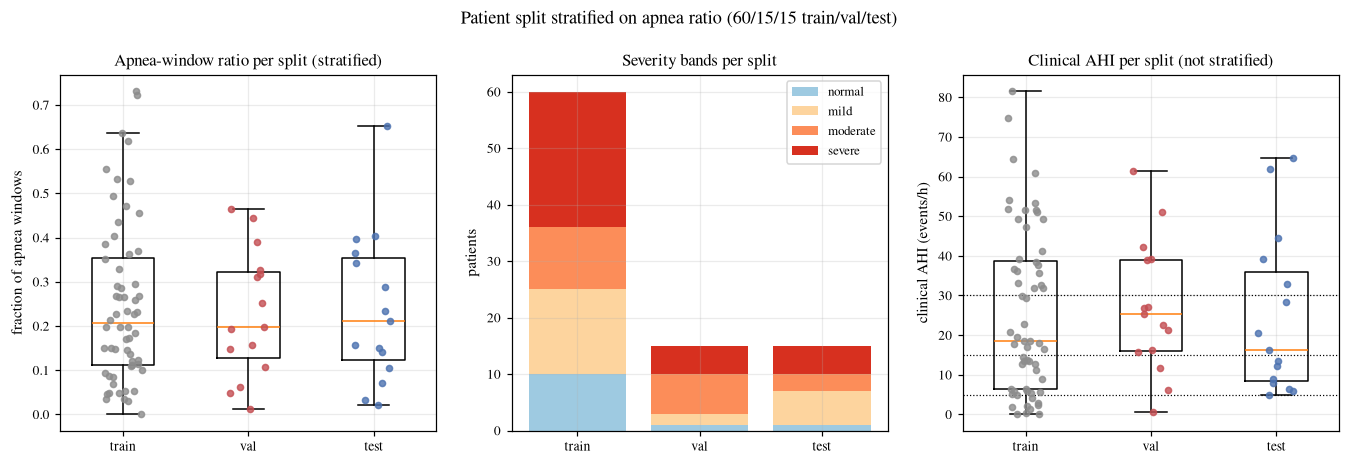

In [5]:
# =============================================================================
# 5. PATIENT-LEVEL SPLIT — ORIGINAL SCHEME (apnea-ratio stratified, exact counts)
#    Same as the Kaggle SE-ResNet cells: rank patients by apnea-window ratio,
#    5 bins, shuffle inside each bin (rng seed 42), round-robin interleave,
#    then slice 60 train / 15 test / 15 val.
#    Clinical AHI from cell 4 is still used for EVALUATION (severity, AHI
#    agreement) — only the split changes.
# =============================================================================
import shutil

STRATIFY_ON = "apnea_ratio"          # "apnea_ratio" = original code | "clinical_ahi" = previous version
REPRODUCE_KAGGLE_SPLIT = True        # rank exactly the 90 patients the Kaggle notebook ranked
KAGGLE_SKIP = {"SN1", "SN28", "SN14", "SN13", "SN17", "SN18",
               "SN19", "SN20", "SN27", "SN89"}          # the original 10-patient skip list


def original_split(pids_, rank_vals, train_n, test_n, val_n, n_bins, seed):
    """Verbatim logic of the Kaggle cell (np.argsort default kind, same RNG calls)."""
    rng = np.random.default_rng(seed)
    order = np.argsort(np.asarray(rank_vals))
    sorted_p = np.array(pids_)[order]
    edges = np.linspace(0, len(sorted_p), n_bins + 1).astype(int)
    bins = []
    for b in range(n_bins):
        bucket = list(sorted_p[edges[b]:edges[b + 1]])
        rng.shuffle(bucket)
        bins.append(bucket)
    combined = [str(p) for grp in zip_longest(*bins, fillvalue=None) for p in grp if p is not None]
    if len(combined) != train_n + test_n + val_n:
        print(f"note: {len(combined)} ranked patients vs requested "
              f"{train_n}+{test_n}+{val_n}={train_n + test_n + val_n}")
    tr = combined[:train_n]
    te = combined[train_n:train_n + test_n]
    va = combined[train_n + test_n:train_n + test_n + val_n]
    return tr, va, te, combined[train_n + test_n + val_n:]


def apnea_ratio_of(pid):
    y = LABELS.get(pid)
    if y is None:                                    # e.g. SN53: skipped here, ranked in Kaggle
        y = np.load(os.path.join(DATA_DIR, f"y_{pid}.npy"), mmap_mode="r")
    return int(np.sum(y)) / max(1, len(y))          # identical to the original formula


# ---- which patients get ranked, on what ------------------------------------
if STRATIFY_ON == "apnea_ratio" and REPRODUCE_KAGGLE_SPLIT:
    # original: lexicographic file order (SN10 before SN2) minus the original skip list
    pool = sorted(f[2:-4] for f in os.listdir(DATA_DIR)
                  if f.startswith("X_SN") and f.endswith(".npy"))
    pool = [p for p in pool if p not in KAGGLE_SKIP
            and os.path.exists(os.path.join(DATA_DIR, f"y_{p}.npy"))]
    rank_vals = [apnea_ratio_of(p) for p in pool]
elif STRATIFY_ON == "apnea_ratio":
    pool, rank_vals = PATIENTS.patient.tolist(), PATIENTS.apnea_ratio.values
elif STRATIFY_ON == "clinical_ahi":
    pool, rank_vals = PATIENTS.patient.tolist(), PATIENTS.strat_ahi.values
else:
    raise ValueError(f"unknown STRATIFY_ON={STRATIFY_ON!r}")

if SMOKE_TEST:     # fit whatever number of fake patients exists
    TEST_N = VAL_N = max(3, len(pool) // 5)
    TRAIN_N = len(pool) - TEST_N - VAL_N

train_pids, val_pids, test_pids, unused_pids = original_split(
    pool, rank_vals, TRAIN_N, TEST_N, VAL_N, N_STRAT_BINS, SEED)

# patients ranked by the original code but excluded here (SN53) are dropped
# from whichever split they landed in; every other patient keeps its original split
usable = set(PATIENTS.patient)
for name, lst in [("train", train_pids), ("val", val_pids), ("test", test_pids)]:
    gone = [p for p in lst if p not in usable]
    if gone:
        print(f"removed from {name}: {gone} ({[SKIP_PATIENTS.get(p, 'not usable') for p in gone]})")
        lst[:] = [p for p in lst if p in usable]
unused_pids = [p for p in unused_pids if p in usable]
left_out = sorted(usable - set(train_pids) - set(val_pids) - set(test_pids), key=pid_num)
if left_out:
    print("usable but not assigned to any split:", left_out)

new_split = dict(train=train_pids, val=val_pids, test=test_pids)

# ---- if a run with a DIFFERENT split already exists, archive it -------------
split_json = os.path.join(SPLIT_DIR, "split.json")
if os.path.exists(split_json):
    old = json.load(open(split_json))
    if any(old.get(k) != v for k, v in new_split.items()):
        arch = os.path.join(OUTPUT_DIR, f"_archive_{old.get('stratify_key', 'clinical_ahi')}_"
                                        f"{time.strftime('%Y%m%d_%H%M%S')}")
        os.makedirs(arch)
        for name in ("split", "models", "tables", "figures", "channel_norm.npz"):
            src = os.path.join(OUTPUT_DIR, name)
            if os.path.exists(src):
                shutil.move(src, os.path.join(arch, name))
        for d in (SPLIT_DIR, MODEL_DIR, TABLE_DIR, FIG_DIR):
            os.makedirs(d, exist_ok=True)
        m = os.path.join(arch, "split", "subject_ahi_mapping.csv")   # written by cell 4 this run
        if os.path.exists(m):
            shutil.copy(m, SPLIT_DIR)
        print(f"Previous results used a different split -> moved to\n  {arch}\n"
              "  (all three models will be retrained on the new split)")

SPLIT_OF = {**{p: "train" for p in train_pids}, **{p: "val" for p in val_pids},
            **{p: "test" for p in test_pids}}
PATIENTS["split"] = PATIENTS.patient.map(SPLIT_OF).fillna("unused")
PATIENTS.to_csv(os.path.join(SPLIT_DIR, "patient_split.csv"), index=False)
with open(split_json, "w") as fh:
    json.dump(dict(**new_split, unused=unused_pids + left_out, seed=SEED,
                   stratify_key=STRATIFY_ON, reproduce_kaggle=REPRODUCE_KAGGLE_SPLIT,
                   ranked_pool=list(pool)), fh, indent=2)

for name, lst in [("train", train_pids), ("val", val_pids), ("test", test_pids)]:
    print(f"{name:5s} ({len(lst):2d}): {sorted(lst, key=pid_num)}")

split_summary = (PATIENTS[PATIENTS.split != "unused"]
                 .groupby("split")
                 .agg(patients=("patient", "count"), windows=("n_windows", "sum"),
                      hours=("hours", "sum"), apnea_ratio=("apnea_ratio", "mean"),
                      ahi_mean=("strat_ahi", "mean"), ahi_median=("strat_ahi", "median"),
                      ahi_min=("strat_ahi", "min"), ahi_max=("strat_ahi", "max"))
                 .reindex(["train", "val", "test"]).reset_index())
sev_ct = pd.crosstab(PATIENTS.split, PATIENTS.severity).reindex(
    index=["train", "val", "test"], columns=SEVERITY_NAMES, fill_value=0)
split_summary = split_summary.merge(sev_ct.reset_index(), on="split")
split_summary["positive_windows_%"] = [
    100 * np.mean(np.concatenate([LABELS[p] for p in PATIENTS.patient[PATIENTS.split == s]]))
    for s in split_summary.split]
save_table(split_summary.round(3), "T0_split_summary")
display(split_summary.round(3))

missing = [s for s in SEVERITY_NAMES if sev_ct.loc["test", s] == 0]
if missing:
    print("\n" + "!" * 70 + f"\n  WARNING: test split has no {missing} patients (by clinical AHI) —\n"
          "  severity metrics cover fewer bands. Report this alongside the results.\n" + "!" * 70)

# split figure
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
order = ["train", "val", "test"]
sc = {"train": "#8C8C8C", "val": "#C44E52", "test": "#4C72B0"}
for k, (col, ylab, title) in enumerate([
        ("apnea_ratio", "fraction of apnea windows", "Apnea-window ratio per split (stratified)"),
        ("strat_ahi", "clinical AHI (events/h)", "Clinical AHI per split (not stratified)")]):
    a = ax[0] if k == 0 else ax[2]
    for i, s in enumerate(order):
        v = PATIENTS[col][PATIENTS.split == s].values
        a.boxplot(v, positions=[i], widths=0.5, showfliers=False)
        a.scatter(np.full(len(v), i) + np.random.default_rng(k).uniform(-.15, .15, len(v)),
                  v, s=16, color=sc[s], alpha=.8, zorder=3)
    a.set_xticks(range(3)); a.set_xticklabels(order)
    a.set_ylabel(ylab); a.set_title(title)
for cut in AHI_BINS:
    ax[2].axhline(cut, ls=":", c="k", lw=.8)
bottom = np.zeros(3)
for sev, colr in zip(SEVERITY_NAMES, ["#9ecae1", "#fdd49e", "#fc8d59", "#d7301f"]):
    vals = sev_ct[sev].values
    ax[1].bar(order, vals, bottom=bottom, color=colr, label=sev)
    bottom += vals
ax[1].set_ylabel("patients"); ax[1].legend(); ax[1].set_title("Severity bands per split")
fig.suptitle(f"Patient split stratified on {STRATIFY_ON.replace('_', ' ')} "
             f"({len(train_pids)}/{len(val_pids)}/{len(test_pids)} train/val/test)", y=1.02)
savefig(fig, "F00_split_overview")

In [6]:
# =============================================================================
# 6. NORMALISATION, SIGNAL CLEANING, SOFT LABELS, DATASET
# =============================================================================
def estimate_norm_stats(patient_ids, n_sample_windows):
    """Per-channel mean/std from a random sample of TRAIN windows only."""
    sums = np.zeros(NUM_CHANNELS); sq = np.zeros(NUM_CHANNELS); count = 0
    budget = max(1, n_sample_windows // max(1, len(patient_ids)))
    for pid in patient_ids:
        X = np.load(os.path.join(DATA_DIR, f"X_{pid}.npy"), mmap_mode="r")
        if X.shape[0] == 0:
            continue
        k = min(budget, X.shape[0])
        idx = np.sort(np.random.default_rng(SEED).choice(X.shape[0], size=k, replace=False))
        s = X[idx].astype(np.float64)
        sums += s.sum(axis=(0, 2)); sq += (s ** 2).sum(axis=(0, 2)); count += k * s.shape[2]
        del X, s
    mean = sums / count
    std = np.sqrt(np.clip(sq / count - mean ** 2, 1e-8, None))
    return mean.astype(np.float32), std.astype(np.float32)

norm_path = os.path.join(OUTPUT_DIR, "channel_norm.npz")
if RESUME and os.path.exists(norm_path):
    _n = np.load(norm_path, allow_pickle=True)
    if list(_n["train_pids"]) == list(train_pids):
        CH_MEAN, CH_STD = _n["mean"], _n["std"]
        print("Loaded normalisation stats")
    else:
        raise RuntimeError("Saved normalisation stats belong to a different split. "
                           "Delete channel_norm.npz / models/ or set RESUME=False.")
else:
    print("Estimating per-channel normalisation stats from TRAIN patients ...")
    CH_MEAN, CH_STD = estimate_norm_stats(train_pids, NORM_SAMPLE_WINDOWS)
    np.savez(norm_path, mean=CH_MEAN, std=CH_STD, train_pids=np.array(train_pids))
print(pd.DataFrame({"channel": FIXED_CHANNEL_KEYS, "mean": CH_MEAN, "std": CH_STD}).round(4).to_string(index=False))


def flatline_mask(sig, min_run):
    """True where the signal stays exactly constant for >= min_run samples.
    Vectorised run-length version of the original loop (same result, much faster)."""
    n = len(sig)
    if n < 2:
        return np.zeros(n, dtype=bool)
    change = np.flatnonzero(sig[1:] != sig[:-1]) + 1
    starts = np.concatenate(([0], change))
    lengths = np.diff(np.concatenate((starts, [n])))
    return np.repeat(lengths >= min_run, lengths)


def clean_signal(sig, valid_range=None, flatline_min_run=FLATLINE_MIN_RUN):
    sig = sig.astype(np.float32, copy=True)
    bad = flatline_mask(sig, flatline_min_run)
    if valid_range is not None:
        bad |= (sig < valid_range[0]) | (sig > valid_range[1])
    if bad.any() and not bad.all():
        good = np.flatnonzero(~bad)
        badi = np.flatnonzero(bad)
        sig[badi] = np.interp(badi, good, sig[good])
    return sig


def clean_spo2_pleth(x):
    x[SPO2_IDX] = clean_signal(x[SPO2_IDX], valid_range=SPO2_VALID_RANGE)
    x[PLETH_IDX] = clean_signal(x[PLETH_IDX], valid_range=None)
    return x


def compute_boundary_soft_labels(y, soft_conf=BOUNDARY_SOFT_CONF):
    """Windows next to a label change get a softened target (train only)."""
    y = np.asarray(y).astype(np.int8)
    soft = y.astype(np.float32)
    boundary = np.zeros(len(y), dtype=bool)
    if len(y) > 1:
        ch = y[1:] != y[:-1]
        boundary[1:] |= ch
        boundary[:-1] |= ch
    soft[boundary & (y == 1)] = 1.0 - soft_conf
    soft[boundary & (y == 0)] = soft_conf
    return soft


class ApneaDataset(Dataset):
    """Window i of a patient + `context_radius` neighbours on each side
    (edge-clamped), concatenated along time -> (8, (2r+1)*6000)."""

    def __init__(self, patient_ids, context_radius, augment=False, use_soft_labels=False):
        self.r = context_radius
        self.augment = augment
        self.use_soft = use_soft_labels
        self.mean = CH_MEAN.reshape(NUM_CHANNELS, 1)
        self.std = CH_STD.reshape(NUM_CHANNELS, 1)
        self._mm = {}
        self.index = []                               # (pid, local_idx, n)
        self.targets = {}
        for pid in patient_ids:
            y = LABELS[pid]
            self.index.extend((pid, i, len(y)) for i in range(len(y)))
            self.targets[pid] = (compute_boundary_soft_labels(y) if use_soft_labels
                                 else y.astype(np.float32))

    def _X(self, pid):
        if pid not in self._mm:
            self._mm[pid] = np.load(os.path.join(DATA_DIR, f"X_{pid}.npy"), mmap_mode="r")
        return self._mm[pid]

    def __len__(self):
        return len(self.index)

    def hard_labels(self):
        return np.array([LABELS[p][i] for p, i, _ in self.index], dtype=np.int8)

    def meta(self):
        return (np.array([p for p, _, _ in self.index]),
                np.array([i for _, i, _ in self.index], dtype=np.int32))

    def __getitem__(self, k):
        pid, i, n = self.index[k]
        X = self._X(pid)
        lo, hi = i - self.r, i + self.r + 1
        if lo >= 0 and hi <= n:                       # fast path: one contiguous slice
            x = np.asarray(X[lo:hi], dtype=np.float32)
        else:
            x = np.asarray(X[np.clip(np.arange(lo, hi), 0, n - 1)], dtype=np.float32)
        x = x.transpose(1, 0, 2).reshape(NUM_CHANNELS, -1)    # (8, (2r+1)*6000)

        x = clean_spo2_pleth(x)
        x = (x - self.mean) / self.std

        if self.augment:
            if NOISE_STD_FRAC > 0:
                x = x + np.random.randn(*x.shape).astype(np.float32) * NOISE_STD_FRAC
            if SCALE_JITTER > 0:
                x = x * (1.0 + (np.random.rand(NUM_CHANNELS, 1).astype(np.float32) * 2 - 1)
                         * SCALE_JITTER)
            if MAX_TIME_SHIFT > 0:
                s = np.random.randint(-MAX_TIME_SHIFT, MAX_TIME_SHIFT + 1)
                if s:
                    x = np.roll(x, s, axis=1)
            if CHANNEL_DROPOUT_P > 0 and np.random.rand() < CHANNEL_DROPOUT_P:
                x[np.random.randint(0, NUM_CHANNELS), :] = 0.0

        y = self.targets[pid][i]
        return torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)), \
               torch.tensor(y, dtype=torch.float32)

# quick shape check
for r in RADII:
    _x, _y = ApneaDataset(train_pids[:1], r)[0]
    print(f"radius {r}: input {tuple(_x.shape)}  ({_x.shape[1] / FS:.0f} s)")

Estimating per-channel normalisation stats from TRAIN patients ...
channel       mean        std
   flow   0.356900 198.427704
  chest   5.267500 213.905197
    abd  14.817300 113.875397
   spo2  93.329498  16.917700
  pleth 382.305115 132.822296
    ecg   1.071600 135.687607
  pulse  67.111397  19.766800
  flow2  -8.944400 133.850693
radius 0: input (8, 6000)  (30 s)
radius 1: input (8, 18000)  (90 s)
radius 2: input (8, 30000)  (150 s)


In [7]:
# =============================================================================
# 7. SE-RESNET1D  (unchanged from the Kaggle SE-ResNet scripts)
# =============================================================================
class SEBlock1D(nn.Module):
    """Squeeze-and-excitation: global-average each feature channel, pass through a
    small bottleneck MLP, and re-scale every channel by a learned gate in (0, 1).
    Because the gate is computed from THIS input, the network can turn channels
    up or down per recording (e.g. a flat or missing sensor)."""

    def __init__(self, channels, reduction=SE_REDUCTION):
        super().__init__()
        hidden = max(4, channels // reduction)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, hidden), nn.ReLU(inplace=True),
            nn.Linear(hidden, channels), nn.Sigmoid(),
        )

    def forward(self, x):
        b, c, _ = x.shape
        return x * self.fc(self.pool(x).view(b, c)).view(b, c, 1)


class SEBasicBlock1D(nn.Module):
    expansion = 1

    def __init__(self, in_planes, planes, stride=1, downsample=None, k=7):
        super().__init__()
        pad = k // 2
        self.conv1 = nn.Conv1d(in_planes, planes, kernel_size=k, stride=stride, padding=pad, bias=False)
        self.bn1 = nn.BatchNorm1d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(planes, planes, kernel_size=k, stride=1, padding=pad, bias=False)
        self.bn2 = nn.BatchNorm1d(planes)
        self.se = SEBlock1D(planes)
        self.downsample = downsample

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.se(self.bn2(self.conv2(out)))
        if self.downsample is not None:
            identity = self.downsample(x)
        return self.relu(out + identity)


class ResNet1D(nn.Module):
    """SE-ResNet1D: stem (k15, /2) + maxpool (/2) -> 4 SE stages [2,2,3,2]
    (/1,/2,/2,/2) -> global average pool -> dropout -> single logit.
    Length-agnostic, so r=0/1/2 use the SAME network."""

    def __init__(self, in_channels=8, base_width=32, dropout=0.4, layers=SE_LAYERS):
        super().__init__()
        self.in_planes = base_width
        self.stem = nn.Sequential(
            nn.Conv1d(in_channels, base_width, kernel_size=15, stride=2, padding=7, bias=False),
            nn.BatchNorm1d(base_width),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=3, stride=2, padding=1),
        )
        self.layer1 = self._make_layer(base_width, layers[0], stride=1)
        self.layer2 = self._make_layer(base_width * 2, layers[1], stride=2)
        self.layer3 = self._make_layer(base_width * 4, layers[2], stride=2)
        self.layer4 = self._make_layer(base_width * 8, layers[3], stride=2)
        self.avgpool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(base_width * 8, 1)

        for m in self.modules():
            if isinstance(m, nn.Conv1d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, planes, num_blocks, stride):
        downsample = None
        if stride != 1 or self.in_planes != planes:
            downsample = nn.Sequential(
                nn.Conv1d(self.in_planes, planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(planes),
            )
        blocks = [SEBasicBlock1D(self.in_planes, planes, stride, downsample)]
        self.in_planes = planes
        for _ in range(1, num_blocks):
            blocks.append(SEBasicBlock1D(self.in_planes, planes))
        return nn.Sequential(*blocks)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        x = self.avgpool(x).squeeze(-1)
        return self.fc(self.dropout(x)).squeeze(-1)


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

_m = ResNet1D(NUM_CHANNELS, BASE_WIDTH, DROPOUT)
N_PARAMS = count_params(_m)
print(f"{MODEL_NAME} parameters: {N_PARAMS:,}   (Kaggle: 2,466,697)")
for r in RADII:
    L = (2 * r + 1) * SAMPLES_PER_WIN
    print(f"  r={r}: {L:>6} samples ({L // FS:>3} s) -> {math.ceil(L / 32)} time steps "
          f"enter the global average pool")
del _m

SE-ResNet1D parameters: 2,466,697   (Kaggle: 2,466,697)
  r=0:   6000 samples ( 30 s) -> 188 time steps enter the global average pool
  r=1:  18000 samples ( 90 s) -> 563 time steps enter the global average pool
  r=2:  30000 samples (150 s) -> 938 time steps enter the global average pool


In [8]:
# =============================================================================
# 8. WEIGHTED FOCAL LOSS
# =============================================================================
class WeightedFocalLoss(nn.Module):
    """FL = (1 - p_t)^gamma * BCEWithLogits(pos_weight).
    pos_weight up-weights the minority (apnea) class; (1 - p_t)^gamma
    down-weights windows the model already gets right. p_t is computed
    against the (possibly soft) target, so boundary soft labels work."""

    def __init__(self, gamma=2.0, pos_weight=None):
        super().__init__()
        self.gamma = gamma
        self.register_buffer("pos_weight", pos_weight if pos_weight is not None else None)

    def forward(self, logits, targets):
        logits = logits.float()
        bce = F.binary_cross_entropy_with_logits(
            logits, targets, pos_weight=self.pos_weight, reduction="none")
        p = torch.sigmoid(logits)
        pt = p * targets + (1 - p) * (1 - targets)
        return ((1 - pt).clamp(min=1e-6) ** self.gamma * bce).mean()

In [9]:
# =============================================================================
# 9. TRAIN / PREDICT
# =============================================================================
def best_f1_threshold(labels, probs):
    labels = np.asarray(labels).astype(int)
    if labels.min() == labels.max():
        return 0.5, 0.0
    prec, rec, thr = precision_recall_curve(labels, probs)
    f1s = 2 * prec * rec / (prec + rec + 1e-9)
    i = int(np.nanargmax(f1s[:-1]))
    return float(thr[i]), float(f1s[i])


def make_loader(ds, batch_size, shuffle, drop_last=False):
    kw = dict(batch_size=batch_size, shuffle=shuffle, drop_last=drop_last,
              num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
    if NUM_WORKERS > 0:
        kw.update(persistent_workers=True, prefetch_factor=4, worker_init_fn=worker_init_fn)
    return DataLoader(ds, **kw)


def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    tot, n, probs, targs = 0.0, 0, [], []
    for X, y in loader:
        X = X.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type=DEVICE.type, enabled=AMP_ON):
                logits = model(X)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                scaler.step(optimizer)
                scaler.update()
        tot += loss.item() * X.size(0); n += X.size(0)
        if not train:
            probs.append(torch.sigmoid(logits.float()).cpu().numpy())
            targs.append(y.cpu().numpy())
    out = tot / max(1, n)
    if train:
        return out, None, None
    return out, np.concatenate(targs), np.concatenate(probs)


def safe_auc(y, p):
    return roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan


def safe_ap(y, p):
    return average_precision_score(y, p) if len(np.unique(y)) == 2 else np.nan


def train_one_model(radius):
    tag = f"r{radius}"
    mdir = os.path.join(MODEL_DIR, tag)
    os.makedirs(mdir, exist_ok=True)
    pred_path = os.path.join(mdir, "predictions.npz")
    hist_path = os.path.join(mdir, "history.csv")
    info_path = os.path.join(mdir, "run_info.json")

    if RESUME and all(os.path.exists(p) for p in (pred_path, hist_path, info_path)):
        info = json.load(open(info_path))
        if (info.get("test_pids") == test_pids and info.get("train_pids") == train_pids
                and info.get("model") == MODEL_NAME):
            print(f"[{tag}] found finished run -> loading (set RESUME=False to retrain)")
            z = np.load(pred_path, allow_pickle=True)
            return dict(radius=radius, history=pd.read_csv(hist_path), info=info,
                        val=dict(pid=z["val_pid"], idx=z["val_idx"], y=z["val_y"], p=z["val_p"]),
                        test=dict(pid=z["test_pid"], idx=z["test_idx"], y=z["test_y"], p=z["test_p"]))
        print(f"[{tag}] saved run used a different split -> retraining")

    seed_everything(SEED)          # every radius starts from the same RNG state
    print(f"\n{'#' * 72}\n#  TRAINING {MODEL_LABEL[radius]}\n{'#' * 72}")
    train_ds = ApneaDataset(train_pids, radius, augment=AUGMENT, use_soft_labels=True)
    val_ds = ApneaDataset(val_pids, radius)
    test_ds = ApneaDataset(test_pids, radius)
    bs = BATCH_SIZE[radius]
    train_ld = make_loader(train_ds, bs, shuffle=True, drop_last=True)
    val_ld = make_loader(val_ds, bs * 2, shuffle=False)
    test_ld = make_loader(test_ds, bs * 2, shuffle=False)

    yh = train_ds.hard_labels()
    n0, n1 = int((yh == 0).sum()), int((yh == 1).sum())
    pw = n0 / max(1, n1)
    if POS_WEIGHT_CAP is not None:
        pw = min(pw, POS_WEIGHT_CAP)
    print(f"  train windows {len(train_ds):,} (normal {n0:,} / apnea {n1:,}) | "
          f"pos_weight {pw:.3f} | batch {bs} | input {(2 * radius + 1) * SAMPLES_PER_WIN} samples")

    model = ResNet1D(NUM_CHANNELS, BASE_WIDTH, DROPOUT).to(DEVICE)
    criterion = WeightedFocalLoss(FOCAL_GAMMA, torch.tensor([pw], dtype=torch.float32)).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=4)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ON)

    best_f1, best_state, best_epoch, bad = -1.0, None, 0, 0
    hist = []
    t_start = time.time()
    for ep in range(1, EPOCHS + 1):
        t0 = time.time()
        tr_loss, _, _ = run_epoch(model, train_ld, criterion, optimizer, scaler)
        va_loss, vy, vp = run_epoch(model, val_ld, criterion)
        thr, f1t = best_f1_threshold(vy, vp)
        f105 = f1_score(vy.astype(int), (vp >= SELECT_THRESHOLD).astype(int), zero_division=0)
        auc, ap = safe_auc(vy, vp), safe_ap(vy, vp)
        sel = f105                                   # Kaggle: select + schedule on val F1 @ 0.5
        scheduler.step(sel)
        dt = time.time() - t0
        hist.append(dict(epoch=ep, train_loss=tr_loss, val_loss=va_loss, val_auroc=auc,
                         val_auprc=ap, val_f1_05=f105, val_f1_tuned=f1t, val_threshold=thr,
                         lr=optimizer.param_groups[0]["lr"], seconds=dt))
        flag = ""
        if sel > best_f1:
            best_f1, best_epoch, bad = sel, ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(dict(state_dict=best_state, model=MODEL_NAME, radius=radius, epoch=ep, val_f1_05=f105,
                            val_threshold=thr, pos_weight=pw, norm_mean=CH_MEAN, norm_std=CH_STD),
                       os.path.join(mdir, "best_model.pt"))
            flag = "  *"
        else:
            bad += 1
        print(f"  [{tag}] ep {ep:2d}/{EPOCHS} | train {tr_loss:.4f} | val {va_loss:.4f} | "
              f"AUROC {auc:.4f} | AUPRC {ap:.4f} | F1@.5 {f105:.4f} | F1@{thr:.2f} {f1t:.4f} | "
              f"{dt:.0f}s{flag}")
        if bad >= PATIENCE:
            print(f"  [{tag}] early stop (best epoch {best_epoch})")
            break
    train_minutes = (time.time() - t_start) / 60

    model.load_state_dict(best_state)
    _, vy, vp = run_epoch(model, val_ld, criterion)
    t0 = time.time()
    _, ty, tp = run_epoch(model, test_ld, criterion)
    infer_ms = 1000 * (time.time() - t0) / max(1, len(test_ds))
    vpid, vidx = val_ds.meta()
    tpid, tidx = test_ds.meta()

    np.savez_compressed(pred_path, val_pid=vpid, val_idx=vidx, val_y=vy.astype(np.int8), val_p=vp,
                        test_pid=tpid, test_idx=tidx, test_y=ty.astype(np.int8), test_p=tp)
    hdf = pd.DataFrame(hist)
    hdf.to_csv(hist_path, index=False)
    info = dict(model=MODEL_NAME, radius=radius, params=count_params(model), best_epoch=best_epoch,
                epochs_run=len(hist), best_val_f1_at_05=best_f1, pos_weight=pw,
                train_minutes=train_minutes, infer_ms_per_window=infer_ms,
                input_samples=(2 * radius + 1) * SAMPLES_PER_WIN, batch_size=bs,
                train_pids=train_pids, val_pids=val_pids, test_pids=test_pids)
    json.dump(info, open(info_path, "w"), indent=2)
    print(f"  [{tag}] done: {train_minutes:.1f} min | test AUROC {safe_auc(ty, tp):.4f}")

    del model, optimizer, train_ld, val_ld, test_ld
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return dict(radius=radius, history=hdf, info=info,
                val=dict(pid=vpid, idx=vidx, y=vy.astype(np.int8), p=vp),
                test=dict(pid=tpid, idx=tidx, y=ty.astype(np.int8), p=tp))

## Train the three models
Each model prints one line per epoch. `*` marks a new best validation F1 at threshold
0.5 (the Kaggle selection rule) — that checkpoint is the one evaluated on the test set.
r=2 is the slowest (5× longer inputs). Kaggle reference for r=2: best val F1@0.5 = 0.5866.

In [10]:
RUNS = {}
for r in RADII:
    RUNS[r] = train_one_model(r)
print("\nAll models ready:", [MODEL_LABEL[r] for r in RUNS])


########################################################################
#  TRAINING SE-ResNet1D r=0 (30 s)
########################################################################
  train windows 57,913 (normal 43,535 / apnea 14,378) | pos_weight 3.028 | batch 32 | input 6000 samples
  [r0] ep  1/16 | train 0.2067 | val 0.2145 | AUROC 0.7630 | AUPRC 0.4904 | F1@.5 0.4932 | F1@0.50 0.4936 | 15s  *
  [r0] ep  2/16 | train 0.1825 | val 0.2093 | AUROC 0.8007 | AUPRC 0.5574 | F1@.5 0.5312 | F1@0.47 0.5480 | 14s  *
  [r0] ep  3/16 | train 0.1756 | val 0.2080 | AUROC 0.8065 | AUPRC 0.5448 | F1@.5 0.5534 | F1@0.50 0.5549 | 13s  *
  [r0] ep  4/16 | train 0.1695 | val 0.2203 | AUROC 0.7848 | AUPRC 0.5537 | F1@.5 0.5280 | F1@0.56 0.5373 | 14s
  [r0] ep  5/16 | train 0.1658 | val 0.1988 | AUROC 0.8151 | AUPRC 0.5857 | F1@.5 0.5545 | F1@0.51 0.5575 | 13s  *
  [r0] ep  6/16 | train 0.1610 | val 0.2106 | AUROC 0.8017 | AUPRC 0.5749 | F1@.5 0.5559 | F1@0.52 0.5621 | 14s  *
  [r0] ep  7/16 | train 0.

In [11]:
# =============================================================================
# 10. METRIC TOOLBOX
# =============================================================================
VARIANTS = ["raw@0.5", "raw@tuned", "smooth@0.5", "smooth@tuned"]


def smooth_grouped(pid_arr, probs, radius=SMOOTH_RADIUS):
    """Moving average inside each patient's time-ordered sequence (never across patients)."""
    out = np.empty_like(probs, dtype=np.float64)
    k = np.ones(2 * radius + 1) / (2 * radius + 1)
    for s, e in patient_bounds(pid_arr):
        out[s:e] = np.convolve(np.pad(probs[s:e], radius, mode="edge"), k, mode="valid")
    return out


def patient_bounds(pid_arr):
    """[(start, end)] of consecutive same-patient blocks (loader is not shuffled)."""
    change = np.flatnonzero(pid_arr[1:] != pid_arr[:-1]) + 1
    starts = np.concatenate(([0], change))
    ends = np.concatenate((change, [len(pid_arr)]))
    return list(zip(starts, ends))


def expected_calibration_error(y, p, n_bins=N_CALIB_BINS):
    edges = np.linspace(0, 1, n_bins + 1)
    b = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    ece = 0.0
    for i in range(n_bins):
        m = b == i
        if m.any():
            ece += m.mean() * abs(p[m].mean() - y[m].mean())
    return ece


def binary_metrics(y, pred):
    y = np.asarray(y).astype(int); pred = np.asarray(pred).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    div = lambda a, b: a / b if b else np.nan
    both_const = len(np.unique(np.concatenate([y, pred]))) < 2
    return dict(
        accuracy=accuracy_score(y, pred),
        balanced_accuracy=balanced_accuracy_score(y, pred) if len(np.unique(y)) == 2 else np.nan,
        precision=div(tp, tp + fp) if (tp + fp) else 0.0,
        sensitivity=div(tp, tp + fn), specificity=div(tn, tn + fp),
        npv=div(tn, tn + fn),
        f1=f1_score(y, pred, zero_division=0),
        f2=fbeta_score(y, pred, beta=2, zero_division=0),
        cohen_kappa=0.0 if both_const else cohen_kappa_score(y, pred),
        mcc=0.0 if both_const else matthews_corrcoef(y, pred),
        youden_j=(div(tp, tp + fn) or 0) + (div(tn, tn + fp) or 0) - 1,
        tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn),
    )


def prob_metrics(y, p):
    y = np.asarray(y).astype(int)
    pc = np.clip(p, 1e-7, 1 - 1e-7)
    two = len(np.unique(y)) == 2
    return dict(
        auroc=safe_auc(y, p), auprc=safe_ap(y, p), prevalence=y.mean(),
        brier=brier_score_loss(y, pc), log_loss=log_loss(y, pc, labels=[0, 1]) if two else np.nan,
        ece=expected_calibration_error(y, p),
    )


def event_match(true_ev, pred_ev, min_frac):
    """Event-level matching.
    min_frac = 0   -> any overlap counts.
    min_frac = 0.5 -> a TRUE event is detected if predicted windows cover >=50% of it;
                      a PREDICTED event is correct if >=50% of it lies on a true event."""
    nt, npd = len(true_ev), len(pred_ev)
    if nt == 0 or npd == 0:
        return 0, 0, nt, npd
    ts, te = true_ev[:, :1], true_ev[:, 1:]
    ps, pe = pred_ev[:, 0][None], pred_ev[:, 1][None]
    ov = np.clip(np.minimum(te, pe) - np.maximum(ts, ps), 0, None)      # (nt, npd)
    if min_frac <= 0:
        hit_t = (ov > 0).any(1); hit_p = (ov > 0).any(0)
    else:
        hit_t = ov.sum(1) >= min_frac * (te - ts).ravel()
        hit_p = ov.sum(0) >= min_frac * (pe - ps).ravel()
    return int(hit_t.sum()), int(hit_p.sum()), nt, npd


def event_match_one_to_one(true_ev, pred_ev):
    """Each true and each predicted event can be used ONCE (greedy, largest overlap
    first). A long predicted run spanning 4 true events is 1 TP + 3 FN here, whereas
    Kaggle-style matching counts it as 4 detected true events."""
    nt, npd = len(true_ev), len(pred_ev)
    if nt == 0 or npd == 0:
        return 0, 0, nt, npd
    ov = np.clip(np.minimum(true_ev[:, 1:], pred_ev[:, 1][None]) -
                 np.maximum(true_ev[:, :1], pred_ev[:, 0][None]), 0, None)
    ti, pj = np.nonzero(ov)
    order = np.argsort(-ov[ti, pj], kind="stable")
    used_t, used_p, m = set(), set(), 0
    for k in order:
        if ti[k] not in used_t and pj[k] not in used_p:
            used_t.add(ti[k]); used_p.add(pj[k]); m += 1
    return m, m, nt, npd


MATCHINGS = [("any overlap (Kaggle)", 0.0), (">=50% overlap", 0.5), ("one-to-one", None)]


def event_metrics(pid_arr, y, pred, min_frac):
    tt = tp_ = nt = npd = 0
    for s, e in patient_bounds(pid_arr):
        te, pe = label_runs(y[s:e]), label_runs(pred[s:e])
        a, b, c, d = (event_match_one_to_one(te, pe) if min_frac is None
                      else event_match(te, pe, min_frac))
        tt += a; tp_ += b; nt += c; npd += d
    prec = tp_ / npd if npd else 0.0
    rec = tt / nt if nt else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return dict(true_events=nt, pred_events=npd, pred_to_true_ratio=npd / nt if nt else np.nan,
                detected_true=tt, correct_pred=tp_,
                event_precision=prec, event_recall=rec, event_f1=f1)


def icc_a1(x, y):
    """ICC(2,1): two-way random effects, absolute agreement, single rater."""
    X = np.column_stack([x, y]).astype(float)
    n, k = X.shape
    if n < 3:
        return np.nan
    gm = X.mean()
    msr = k * ((X.mean(1) - gm) ** 2).sum() / (n - 1)
    msc = n * ((X.mean(0) - gm) ** 2).sum() / (k - 1)
    sse = ((X - X.mean(1, keepdims=True) - X.mean(0, keepdims=True) + gm) ** 2).sum()
    mse = sse / ((n - 1) * (k - 1))
    den = msr + (k - 1) * mse + k * (msc - mse) / n
    return (msr - mse) / den if den else np.nan


def agreement(ref, pred, name):
    ref = np.asarray(ref, float); pred = np.asarray(pred, float)
    m = np.isfinite(ref) & np.isfinite(pred)
    ref, pred = ref[m], pred[m]
    d = pred - ref
    out = dict(comparison=name, n=len(ref))
    if len(ref) >= 3 and ref.std() > 0 and pred.std() > 0:
        r, pr = stats.pearsonr(ref, pred)
        rho, _ = stats.spearmanr(ref, pred)
    else:
        r = pr = rho = np.nan
    out.update(pearson_r=r, pearson_p=pr, spearman_rho=rho,
               mae=np.abs(d).mean() if len(d) else np.nan,
               rmse=np.sqrt((d ** 2).mean()) if len(d) else np.nan,
               bias=d.mean() if len(d) else np.nan,
               loa_low=d.mean() - 1.96 * d.std(ddof=1) if len(d) > 1 else np.nan,
               loa_high=d.mean() + 1.96 * d.std(ddof=1) if len(d) > 1 else np.nan,
               icc_a1=icc_a1(ref, pred))
    return out


def severity_agreement(true_ahi, pred_ahi, name):
    t = np.array([severity_of(a) for a in true_ahi])
    p = np.array([severity_of(max(a, 0)) for a in pred_ahi])
    labels = list(range(len(SEVERITY_NAMES)))
    one = len(np.unique(np.concatenate([t, p]))) < 2
    return dict(
        comparison=name, n=len(t), bands_in_truth=len(np.unique(t)),
        accuracy=accuracy_score(t, p),
        kappa_linear=np.nan if one else cohen_kappa_score(t, p, labels=labels, weights="linear"),
        kappa_quadratic=np.nan if one else cohen_kappa_score(t, p, labels=labels, weights="quadratic"),
        within_one_band=np.mean(np.abs(t - p) <= 1),
    ), confusion_matrix(t, p, labels=labels)


def delong_test(y, p1, p2):
    """Fast DeLong test for two correlated AUROCs (Sun & Xu, 2014)."""
    y = np.asarray(y).astype(int)
    pos, neg = y == 1, y == 0
    m, n = pos.sum(), neg.sum()
    P = np.vstack([p1, p2])
    X, Y = P[:, pos], P[:, neg]
    tx = np.vstack([stats.rankdata(X[i]) for i in range(2)])
    ty = np.vstack([stats.rankdata(Y[i]) for i in range(2)])
    tz = np.vstack([stats.rankdata(np.concatenate([X[i], Y[i]])) for i in range(2)])
    aucs = tz[:, :m].sum(1) / (m * n) - (m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m
    S = np.cov(v01) / m + np.cov(v10) / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    z = (aucs[0] - aucs[1]) / np.sqrt(var) if var > 0 else 0.0
    return aucs[0], aucs[1], z, 2 * stats.norm.sf(abs(z))


def holm(pvals):
    p = np.asarray(pvals, float)
    out = np.full_like(p, np.nan)
    ok = np.isfinite(p)
    idx = np.argsort(p[ok]); pv = p[ok][idx]; k = len(pv)
    adj = np.maximum.accumulate(np.minimum(1, (k - np.arange(k)) * pv))
    tmp = np.empty(k); tmp[idx] = adj
    out[ok] = tmp
    return out


def threshold_sweep(y, p, grid=np.round(np.arange(0.02, 0.99, 0.02), 2)):
    rows = []
    for t in grid:
        m = binary_metrics(y, (p >= t).astype(int))
        rows.append(dict(threshold=t, **{k: m[k] for k in
                   ["precision", "sensitivity", "specificity", "f1", "f2", "cohen_kappa",
                    "mcc", "balanced_accuracy"]}))
    return pd.DataFrame(rows)

In [12]:
# =============================================================================
# 11. EVALUATE EVERY MODEL
# =============================================================================
def per_patient_table(S, score, thr):
    rows = []
    for s, e in patient_bounds(S["pid"]):
        pid = S["pid"][s]; y = S["y"][s:e]; sc = score[s:e]; pr = (sc >= thr).astype(int)
        bm = binary_metrics(y, pr)
        info = PATIENTS.set_index("patient").loc[pid]
        rows.append(dict(
            patient=pid, n_windows=e - s, prevalence=y.mean(),
            clinical_ahi=info.clinical_ahi, strat_ahi=info.strat_ahi, severity=info.severity,
            label_event_index=event_index(y), label_epoch_index=epoch_index(y),
            pred_event_index=event_index(pr), pred_epoch_index=epoch_index(pr),
            auroc=safe_auc(y, sc), auprc=safe_ap(y, sc),
            **{k: bm[k] for k in ["accuracy", "precision", "sensitivity", "specificity",
                                   "f1", "cohen_kappa", "mcc", "tp", "fp", "fn", "tn"]},
        ))
        if y.sum() == 0:            # no scored events: F1 is undefined, not 0
            rows[-1]["f1"] = np.nan
    return pd.DataFrame(rows)


def evaluate_run(run):
    r = run["radius"]
    V, T = run["val"], run["test"]
    V["ps"] = smooth_grouped(V["pid"], V["p"])
    T["ps"] = smooth_grouped(T["pid"], T["p"])
    thr_raw, _ = best_f1_threshold(V["y"], V["p"])
    thr_sm, _ = best_f1_threshold(V["y"], V["ps"])
    var_def = {"raw@0.5": ("p", 0.5), "raw@tuned": ("p", thr_raw),
               "smooth@0.5": ("ps", 0.5), "smooth@tuned": ("ps", thr_sm)}

    window_rows, event_rows, cms, reports = [], [], {}, {}
    for split_name, S in [("val", V), ("test", T)]:
        for vname, (key, thr) in var_def.items():
            sc = S[key]; pr = (sc >= thr).astype(int)
            window_rows.append(dict(model=MODEL_LABEL[r], radius=r, split=split_name,
                                    variant=vname, threshold=thr,
                                    **prob_metrics(S["y"], sc), **binary_metrics(S["y"], pr)))
            if split_name == "test":
                cms[vname] = confusion_matrix(S["y"], pr, labels=[0, 1])
                reports[vname] = classification_report(
                    S["y"], pr, labels=[0, 1], target_names=["Normal", "Apnea"],
                    digits=4, zero_division=0)
                for lab, mf in MATCHINGS:
                    event_rows.append(dict(model=MODEL_LABEL[r], radius=r, variant=vname,
                                           matching=lab, **event_metrics(S["pid"], S["y"], pr, mf)))

    key, thr = var_def[PRIMARY_VARIANT]
    pp_test = per_patient_table(T, T[key], thr)
    pp_val = per_patient_table(V, V[key], thr)

    # ---- AHI / severity ----------------------------------------------------
    idx_col = f"pred_{AHI_PRED_INDEX}_index"
    cal = pp_val.dropna(subset=["clinical_ahi"])
    if len(cal) >= 3 and cal[idx_col].std() > 0:
        slope, intercept = np.polyfit(cal[idx_col], cal.clinical_ahi, 1)
    else:
        slope, intercept = 1.0, 0.0
        print(f"  [{MODEL_LABEL[r]}] AHI calibration skipped (too few val patients)")
    pp_test["pred_ahi_calibrated"] = np.clip(slope * pp_test[idx_col] + intercept, 0, None)
    pp_val["pred_ahi_calibrated"] = np.clip(slope * pp_val[idx_col] + intercept, 0, None)

    tc = pp_test.dropna(subset=["clinical_ahi"])
    ahi_rows = [
        agreement(tc.clinical_ahi, tc.pred_ahi_calibrated,
                  f"calibrated pred ({AHI_PRED_INDEX} index) vs clinical AHI"),
        agreement(tc.clinical_ahi, tc.pred_event_index, "pred event index (raw) vs clinical AHI"),
        agreement(tc.clinical_ahi, tc.pred_epoch_index, "pred epoch index (raw) vs clinical AHI"),
        agreement(pp_test.label_event_index, pp_test.pred_event_index,
                  "pred event index vs label event index"),
        agreement(pp_test.label_epoch_index, pp_test.pred_epoch_index,
                  "pred epoch index vs label epoch index"),
        agreement(tc.clinical_ahi, tc.label_event_index,
                  "REFERENCE: label event index vs clinical AHI (ceiling)"),
    ]
    for a in ahi_rows:
        a.update(model=MODEL_LABEL[r], radius=r)
    ahi_df = pd.DataFrame(ahi_rows)
    ahi_df["calib_slope"], ahi_df["calib_intercept"] = slope, intercept

    sev_rows, sev_cms = [], {}
    for name, pred_col in [("calibrated pred vs clinical", "pred_ahi_calibrated"),
                           ("raw pred event index vs clinical", "pred_event_index")]:
        row, cm = severity_agreement(tc.clinical_ahi.values, tc[pred_col].values, name)
        row.update(model=MODEL_LABEL[r], radius=r)
        sev_rows.append(row); sev_cms[name] = cm

    strata = (pp_test.groupby("severity")
              .agg(n_patients=("patient", "count"), mean_prevalence=("prevalence", "mean"),
                   mean_f1=("f1", "mean"), median_f1=("f1", "median"),
                   mean_auroc=("auroc", "mean"), mean_auprc=("auprc", "mean"),
                   mean_kappa=("cohen_kappa", "mean"), mean_mcc=("mcc", "mean"),
                   mean_sensitivity=("sensitivity", "mean"),
                   mean_specificity=("specificity", "mean"))
              .reindex(SEVERITY_NAMES).reset_index())
    strata.insert(0, "model", MODEL_LABEL[r])

    return dict(radius=r, label=MODEL_LABEL[r], thr_raw=thr_raw, thr_sm=thr_sm,
                var_def=var_def, window=pd.DataFrame(window_rows),
                events=pd.DataFrame(event_rows), cms=cms, reports=reports,
                pp_test=pp_test, pp_val=pp_val, ahi=ahi_df,
                severity=pd.DataFrame(sev_rows), sev_cms=sev_cms, strata=strata,
                sweep=threshold_sweep(T["y"], T[key]),
                calib=(slope, intercept))


EVAL = {}
for r in RADII:
    EVAL[r] = evaluate_run(RUNS[r])
    with open(os.path.join(MODEL_DIR, f"r{r}", "classification_reports.txt"), "w") as fh:
        for v, rep in EVAL[r]["reports"].items():
            fh.write(f"===== {MODEL_LABEL[r]} | TEST | {v} =====\n{rep}\n")
    print(f"{MODEL_LABEL[r]}: val-tuned thr raw={EVAL[r]['thr_raw']:.3f}, "
          f"smoothed={EVAL[r]['thr_sm']:.3f}")

print(f"\nClassification reports — TEST, {PRIMARY_VARIANT}")
for r in RADII:
    print(f"\n--- {MODEL_LABEL[r]} ---\n{EVAL[r]['reports'][PRIMARY_VARIANT]}")

SE-ResNet1D r=0 (30 s): val-tuned thr raw=0.501, smoothed=0.471
SE-ResNet1D r=1 (90 s): val-tuned thr raw=0.501, smoothed=0.476
SE-ResNet1D r=2 (150 s): val-tuned thr raw=0.540, smoothed=0.532

Classification reports — TEST, raw@0.5

--- SE-ResNet1D r=0 (30 s) ---
              precision    recall  f1-score   support

      Normal     0.8756    0.8363    0.8555     11000
       Apnea     0.5394    0.6174    0.5758      3416

    accuracy                         0.7844     14416
   macro avg     0.7075    0.7268    0.7156     14416
weighted avg     0.7959    0.7844    0.7892     14416


--- SE-ResNet1D r=1 (90 s) ---
              precision    recall  f1-score   support

      Normal     0.8884    0.8805    0.8844     11000
       Apnea     0.6260    0.6437    0.6347      3416

    accuracy                         0.8244     14416
   macro avg     0.7572    0.7621    0.7596     14416
weighted avg     0.8262    0.8244    0.8253     14416


--- SE-ResNet1D r=2 (150 s) ---
              pr

In [13]:
# =============================================================================
# 12. PATIENT-LEVEL BOOTSTRAP CONFIDENCE INTERVALS (+ paired differences)
# =============================================================================
BOOT_METRICS = ["auroc", "auprc", "f1", "cohen_kappa", "mcc", "sensitivity", "specificity",
                "balanced_accuracy"]


def _metrics_for(y, sc, thr):
    bm = binary_metrics(y, (sc >= thr).astype(int))
    return dict(auroc=safe_auc(y, sc), auprc=safe_ap(y, sc),
                **{k: bm[k] for k in BOOT_METRICS[2:]})


rng_boot = np.random.default_rng(SEED)
blocks = patient_bounds(RUNS[RADII[0]]["test"]["pid"])      # same test order for every model
for r in RADII:
    assert np.array_equal(RUNS[r]["test"]["pid"], RUNS[RADII[0]]["test"]["pid"]), \
        "test order differs between models"
boot_idx = [rng_boot.integers(0, len(blocks), len(blocks)) for _ in range(N_BOOT)]

BOOT = {r: [] for r in RADII}
for r in RADII:
    T = RUNS[r]["test"]; key, thr = EVAL[r]["var_def"][PRIMARY_VARIANT]
    for bi in boot_idx:
        sel = np.concatenate([np.arange(*blocks[j]) for j in bi])
        BOOT[r].append(_metrics_for(T["y"][sel], T[key][sel], thr))
    BOOT[r] = pd.DataFrame(BOOT[r])

ci_rows = []
for r in RADII:
    T = RUNS[r]["test"]; key, thr = EVAL[r]["var_def"][PRIMARY_VARIANT]
    point = _metrics_for(T["y"], T[key], thr)
    for mname in BOOT_METRICS:
        b = BOOT[r][mname].dropna()
        ci_rows.append(dict(model=MODEL_LABEL[r], radius=r, metric=mname, value=point[mname],
                            ci_low=b.quantile(.025), ci_high=b.quantile(.975), boot_sd=b.std()))
CI = pd.DataFrame(ci_rows)
save_table(CI.round(4), "T2_bootstrap_ci_test")

diff_rows = []
for a, b in combinations(RADII, 2):
    for mname in BOOT_METRICS:
        d = (BOOT[b][mname] - BOOT[a][mname]).dropna()
        pt = CI.query("radius==@b and metric==@mname").value.iloc[0] - \
             CI.query("radius==@a and metric==@mname").value.iloc[0]
        p_two = 2 * min((d <= 0).mean(), (d >= 0).mean())
        diff_rows.append(dict(comparison=f"r{b} - r{a}", metric=mname, delta=pt,
                              ci_low=d.quantile(.025), ci_high=d.quantile(.975),
                              p_bootstrap=min(1.0, p_two)))
BOOT_DIFF = pd.DataFrame(diff_rows)
BOOT_DIFF["p_holm"] = BOOT_DIFF.groupby("metric").p_bootstrap.transform(lambda s: holm(s.values))
save_table(BOOT_DIFF.round(4), "T3_bootstrap_paired_differences")

tbl = CI.assign(txt=lambda d: d.value.map("{:.4f}".format) + " [" +
                d.ci_low.map("{:.3f}".format) + ", " + d.ci_high.map("{:.3f}".format) + "]")
display(Markdown(f"**Test metrics with 95% patient-level bootstrap CI ({PRIMARY_VARIANT}, "
                 f"{N_BOOT} resamples)**"))
display(tbl.pivot(index="metric", columns="model", values="txt").reindex(BOOT_METRICS))
display(Markdown("**Paired bootstrap differences** (positive = larger radius is better)"))
display(BOOT_DIFF.round(4))

**Test metrics with 95% patient-level bootstrap CI (raw@0.5, 1000 resamples)**

model,SE-ResNet1D r=0 (30 s),SE-ResNet1D r=1 (90 s),SE-ResNet1D r=2 (150 s)
metric,,,
auroc,"0.8252 [0.783, 0.862]","0.8662 [0.832, 0.899]","0.8199 [0.734, 0.895]"
auprc,"0.6177 [0.517, 0.698]","0.6988 [0.605, 0.771]","0.6475 [0.522, 0.750]"
f1,"0.5758 [0.507, 0.627]","0.6347 [0.558, 0.695]","0.5831 [0.485, 0.654]"
cohen_kappa,"0.4321 [0.364, 0.489]","0.5192 [0.445, 0.589]","0.4167 [0.306, 0.507]"
mcc,"0.4339 [0.368, 0.492]","0.5193 [0.446, 0.593]","0.4348 [0.313, 0.538]"
sensitivity,"0.6174 [0.514, 0.738]","0.6437 [0.540, 0.758]","0.7327 [0.533, 0.896]"
specificity,"0.8363 [0.756, 0.896]","0.8805 [0.829, 0.918]","0.7576 [0.673, 0.830]"
balanced_accuracy,"0.7268 [0.689, 0.770]","0.7621 [0.718, 0.809]","0.7452 [0.661, 0.817]"


**Paired bootstrap differences** (positive = larger radius is better)

,comparison,metric,delta,ci_low,ci_high,p_bootstrap,p_holm
0,r1 - r0,auroc,0.0411,0.0119,0.0735,0.002,0.006
1,r1 - r0,auprc,0.0811,0.0236,0.1454,0.002,0.006
2,r1 - r0,f1,0.0590,0.0104,0.1140,0.014,0.042
3,r1 - r0,cohen_kappa,0.0871,0.0175,0.1633,0.010,0.024
4,r1 - r0,mcc,0.0854,0.0161,0.1616,0.010,0.030
5,r1 - r0,sensitivity,0.0263,-0.0323,0.0919,0.402,0.402
6,r1 - r0,specificity,0.0443,0.0050,0.0914,0.032,0.032
7,r1 - r0,balanced_accuracy,0.0353,0.0018,0.0748,0.042,0.126
8,r2 - r0,auroc,-0.0052,-0.0891,0.0730,0.986,1.000
9,r2 - r0,auprc,0.0299,-0.0725,0.1416,0.554,0.724


In [14]:
# =============================================================================
# 13. COMPARISON TABLES
# =============================================================================
WIN = pd.concat([EVAL[r]["window"] for r in RADII], ignore_index=True)
save_table(WIN.round(5), "T1a_window_metrics_all_variants_val_and_test", latex=False)

main_cols = ["model", "variant", "threshold", "auroc", "auprc", "accuracy", "balanced_accuracy",
             "precision", "sensitivity", "specificity", "npv", "f1", "f2", "cohen_kappa", "mcc",
             "brier", "ece"]
T1 = WIN.query("split=='test'")[main_cols].reset_index(drop=True)
save_table(T1.round(4), "T1_window_metrics_test")
display(Markdown("### T1 — Window-level test metrics, every model × every decision rule"))
display(T1.round(4))

EVT = pd.concat([EVAL[r]["events"] for r in RADII], ignore_index=True)

# compact headline table (primary variant) — ready for the paper
head_cols = ["model", "auroc", "auprc", "f1", "cohen_kappa", "mcc", "sensitivity",
             "specificity", "precision", "accuracy"]
HEAD = T1.query("variant==@PRIMARY_VARIANT")[head_cols].reset_index(drop=True)
ev_primary = pd.concat([EVAL[r]["events"] for r in RADII]).query(
    "variant==@PRIMARY_VARIANT")
HEAD["event_f1_kaggle"] = ev_primary[ev_primary.matching == "any overlap (Kaggle)"].event_f1.values
HEAD["event_f1_1to1"] = ev_primary[ev_primary.matching == "one-to-one"].event_f1.values
HEAD["true_events"] = ev_primary[ev_primary.matching == "one-to-one"].true_events.values
HEAD["pred_events"] = ev_primary[ev_primary.matching == "one-to-one"].pred_events.values
sev_cal = pd.concat([EVAL[r]["severity"] for r in RADII]).query(
    "comparison=='calibrated pred vs clinical'")
ahi_cal = pd.concat([EVAL[r]["ahi"] for r in RADII])
ahi_cal = ahi_cal[ahi_cal.comparison.str.startswith("calibrated")]
HEAD["ahi_r"] = ahi_cal.pearson_r.values
HEAD["ahi_mae"] = ahi_cal.mae.values
HEAD["severity_acc"] = sev_cal.accuracy.values
HEAD["severity_kappa_w"] = sev_cal.kappa_linear.values
HEAD["params"] = [RUNS[r]["info"]["params"] for r in RADII]
HEAD["best_epoch"] = [RUNS[r]["info"]["best_epoch"] for r in RADII]
HEAD["train_min"] = [RUNS[r]["info"]["train_minutes"] for r in RADII]
HEAD["infer_ms/win"] = [RUNS[r]["info"]["infer_ms_per_window"] for r in RADII]
save_table(HEAD.round(4), "T0_headline_comparison")

# Kaggle reference (SE-ResNet1D, same test patients, threshold 0.5, 1 seed)
KAGGLE_REF = pd.DataFrame([
    dict(run="Kaggle r=2 raw@0.5", auroc=0.8516, f1=0.6198, precision=0.5572, sensitivity=0.6982,
         accuracy=0.7970, event_f1_kaggle=np.nan, pred_events=np.nan),
    dict(run="Kaggle r=2 smooth@0.5", auroc=np.nan, f1=0.6273, precision=0.5690, sensitivity=0.6991,
         accuracy=0.8032, event_f1_kaggle=0.6205, pred_events=257),
    dict(run="Kaggle r=3 raw@0.5", auroc=0.8623, f1=0.6283, precision=0.5188, sensitivity=0.7965,
         accuracy=0.7767, event_f1_kaggle=np.nan, pred_events=np.nan),
    dict(run="Kaggle r=3 smooth@0.5", auroc=np.nan, f1=0.6335, precision=0.5234, sensitivity=0.8024,
         accuracy=0.7800, event_f1_kaggle=0.6586, pred_events=202),
])
mine = []
for r in RADII:
    for v in ["raw@0.5", "smooth@0.5"]:
        w = T1[(T1.model == MODEL_LABEL[r]) & (T1.variant == v)].iloc[0]
        e = EVT[(EVT.radius == r) & (EVT.variant == v) & (EVT.matching == "any overlap (Kaggle)")]
        mine.append(dict(run=f"this notebook r={r} {v}", auroc=w.auroc, f1=w.f1,
                         precision=w.precision, sensitivity=w.sensitivity, accuracy=w.accuracy,
                         event_f1_kaggle=e.event_f1.iloc[0] if v.startswith("smooth") else np.nan,
                         pred_events=e.pred_events.iloc[0] if v.startswith("smooth") else np.nan))
REPRO = pd.concat([pd.DataFrame(mine), KAGGLE_REF], ignore_index=True)
save_table(REPRO.round(4), "T0b_reproduction_vs_kaggle")
display(Markdown(f"### Headline comparison (test, {PRIMARY_VARIANT})"))
display(HEAD.round(4))
display(Markdown("### Reproduction check against the Kaggle SE-ResNet runs "
                 "(same 15 test patients; single seed, so expect a few points of drift)"))
display(REPRO.round(4))

save_table(EVT.round(4), "T4_event_level_test")
display(Markdown("### T4 — Event-level detection (test)"))
display(EVT.round(4))

AHI = pd.concat([EVAL[r]["ahi"] for r in RADII], ignore_index=True)
AHI = AHI[["model", "comparison", "n", "pearson_r", "pearson_p", "spearman_rho", "icc_a1",
           "mae", "rmse", "bias", "loa_low", "loa_high", "calib_slope", "calib_intercept"]]
save_table(AHI.round(4), "T5_ahi_agreement_test")
display(Markdown("### T5 — AHI agreement (test patients)"))
display(AHI.round(4))

SEV = pd.concat([EVAL[r]["severity"] for r in RADII], ignore_index=True)
save_table(SEV.round(4), "T6_severity_agreement_test")
display(Markdown("### T6 — Severity classification (4 AASM bands, test patients)"))
display(SEV.round(4))

STR = pd.concat([EVAL[r]["strata"] for r in RADII], ignore_index=True)
save_table(STR.round(4), "T7_severity_stratified_performance")
display(Markdown("### T7 — Performance stratified by clinical severity (test)"))
display(STR.round(3))

PP = pd.concat([EVAL[r]["pp_test"].assign(model=MODEL_LABEL[r], radius=r) for r in RADII],
               ignore_index=True)
save_table(PP.round(4), "T8_per_patient_test", latex=False)
pp_summary = (PP.groupby("model")[["f1", "auroc", "auprc", "cohen_kappa", "mcc",
                                   "sensitivity", "specificity"]]
              .agg(["mean", "std", "median", "min", "max"]).round(3))
pp_summary.columns = ["_".join(c) for c in pp_summary.columns]
pp_summary = pp_summary.reset_index()
save_table(pp_summary, "T9_per_patient_summary", latex=False)
display(Markdown("### T9 — Per-patient metric distribution (test)"))
display(pp_summary)

HIST = pd.concat([RUNS[r]["history"].assign(model=MODEL_LABEL[r], radius=r) for r in RADII])
save_table(HIST.round(5), "T10_training_history", latex=False)
RUNINFO = pd.DataFrame([{k: v for k, v in RUNS[r]["info"].items() if not k.endswith("_pids")}
                        for r in RADII])
save_table(RUNINFO.round(4), "T11_run_info")
display(RUNINFO.round(3))

### T1 — Window-level test metrics, every model × every decision rule

,model,variant,threshold,auroc,auprc,accuracy,balanced_accuracy,precision,sensitivity,specificity,npv,f1,f2,cohen_kappa,mcc,brier,ece
0,SE-ResNet1D r=0 (30 s),raw@0.5,0.5000,0.8252,0.6177,0.7844,0.7268,0.5394,0.6174,0.8363,0.8756,0.5758,0.6000,0.4321,0.4339,0.1638,0.1644
1,SE-ResNet1D r=0 (30 s),raw@tuned,0.5009,0.8252,0.6177,0.7854,0.7271,0.5415,0.6162,0.8380,0.8755,0.5765,0.5997,0.4336,0.4352,0.1638,0.1644
2,SE-ResNet1D r=0 (30 s),smooth@0.5,0.5000,0.8324,0.6227,0.7983,0.7305,0.5705,0.6016,0.8594,0.8741,0.5856,0.5951,0.4525,0.4527,0.1655,0.1694
3,SE-ResNet1D r=0 (30 s),smooth@tuned,0.4708,0.8324,0.6227,0.7796,0.7473,0.5269,0.6859,0.8087,0.8924,0.5960,0.6468,0.4480,0.4554,0.1655,0.1694
4,SE-ResNet1D r=1 (90 s),raw@0.5,0.5000,0.8662,0.6988,0.8244,0.7621,0.6260,0.6437,0.8805,0.8884,0.6347,0.6401,0.5192,0.5193,0.1431,0.1542
5,SE-ResNet1D r=1 (90 s),raw@tuned,0.5006,0.8662,0.6988,0.8246,0.7613,0.6270,0.6411,0.8815,0.8878,0.6340,0.6382,0.5186,0.5187,0.1431,0.1542
6,SE-ResNet1D r=1 (90 s),smooth@0.5,0.5000,0.8691,0.7099,0.8290,0.7621,0.6404,0.6350,0.8893,0.8869,0.6377,0.6360,0.5258,0.5258,0.1442,0.1632
7,SE-ResNet1D r=1 (90 s),smooth@tuned,0.4762,0.8691,0.7099,0.8219,0.7773,0.6092,0.6926,0.8620,0.9003,0.6482,0.6742,0.5296,0.5316,0.1442,0.1632
8,SE-ResNet1D r=2 (150 s),raw@0.5,0.5000,0.8199,0.6475,0.7517,0.7452,0.4842,0.7327,0.7576,0.9013,0.5831,0.6645,0.4167,0.4348,0.1690,0.1815
9,SE-ResNet1D r=2 (150 s),raw@tuned,0.5398,0.8199,0.6475,0.7809,0.7471,0.5291,0.6830,0.8113,0.8918,0.5963,0.6454,0.4492,0.4561,0.1690,0.1815


### Headline comparison (test, raw@0.5)

,model,auroc,auprc,f1,cohen_kappa,mcc,sensitivity,specificity,precision,accuracy,...,true_events,pred_events,ahi_r,ahi_mae,severity_acc,severity_kappa_w,params,best_epoch,train_min,infer_ms/win
0,SE-ResNet1D r=0 (30 s),0.8252,0.6177,0.5758,0.4321,0.4339,0.6174,0.8363,0.5394,0.7844,...,825,1364,0.6294,11.4973,0.6000,0.5291,2466697,13,3.6629,0.0794
1,SE-ResNet1D r=1 (90 s),0.8662,0.6988,0.6347,0.5192,0.5193,0.6437,0.8805,0.6260,0.8244,...,825,589,0.7459,9.7981,0.6667,0.5909,2466697,6,6.4104,0.2245
2,SE-ResNet1D r=2 (150 s),0.8199,0.6475,0.5831,0.4167,0.4348,0.7327,0.7576,0.4842,0.7517,...,825,509,0.4572,14.3313,0.6000,0.4000,2466697,13,14.3501,0.3226


### Reproduction check against the Kaggle SE-ResNet runs (same 15 test patients; single seed, so expect a few points of drift)

,run,auroc,f1,precision,sensitivity,accuracy,event_f1_kaggle,pred_events
0,this notebook r=0 raw@0.5,0.8252,0.5758,0.5394,0.6174,0.7844,NaN,NaN
1,this notebook r=0 smooth@0.5,0.8324,0.5856,0.5705,0.6016,0.7983,0.5828,345.0
2,this notebook r=1 raw@0.5,0.8662,0.6347,0.6260,0.6437,0.8244,NaN,NaN
3,this notebook r=1 smooth@0.5,0.8691,0.6377,0.6404,0.6350,0.8290,0.6244,265.0
4,this notebook r=2 raw@0.5,0.8199,0.5831,0.4842,0.7327,0.7517,NaN,NaN
5,this notebook r=2 smooth@0.5,0.8221,0.5945,0.5012,0.7304,0.7639,0.6199,274.0
6,Kaggle r=2 raw@0.5,0.8516,0.6198,0.5572,0.6982,0.7970,NaN,NaN
7,Kaggle r=2 smooth@0.5,NaN,0.6273,0.5690,0.6991,0.8032,0.6205,257.0
8,Kaggle r=3 raw@0.5,0.8623,0.6283,0.5188,0.7965,0.7767,NaN,NaN
9,Kaggle r=3 smooth@0.5,NaN,0.6335,0.5234,0.8024,0.7800,0.6586,202.0


... (7 outputs left out)

,model,severity,n_patients,mean_prevalence,mean_f1,median_f1,mean_auroc,mean_auprc,mean_kappa,mean_mcc,mean_sensitivity,mean_specificity
0,SE-ResNet1D r=0 (30 s),normal,1,0.289,0.674,0.674,0.857,0.702,0.532,0.534,0.708,0.840
1,SE-ResNet1D r=0 (30 s),mild,6,0.089,0.382,0.373,0.769,0.353,0.313,0.325,0.480,0.909
2,SE-ResNet1D r=0 (30 s),moderate,3,0.195,0.513,0.534,0.837,0.585,0.359,0.393,0.661,0.756
3,SE-ResNet1D r=0 (30 s),severe,5,0.432,0.628,0.625,0.804,0.756,0.382,0.410,0.631,0.768
4,SE-ResNet1D r=1 (90 s),normal,1,0.289,0.594,0.594,0.814,0.644,0.434,0.434,0.584,0.845
5,SE-ResNet1D r=1 (90 s),mild,6,0.089,0.396,0.442,0.835,0.423,0.346,0.365,0.471,0.941
6,SE-ResNet1D r=1 (90 s),moderate,3,0.195,0.580,0.609,0.861,0.640,0.455,0.474,0.724,0.819
7,SE-ResNet1D r=1 (90 s),severe,5,0.432,0.699,0.704,0.868,0.824,0.499,0.525,0.686,0.831
8,SE-ResNet1D r=2 (150 s),normal,1,0.289,0.647,0.647,0.836,0.677,0.459,0.483,0.813,0.716
9,SE-ResNet1D r=2 (150 s),mild,6,0.089,0.364,0.459,0.809,0.398,0.290,0.327,0.591,0.849


### T9 — Per-patient metric distribution (test)

,model,f1_mean,f1_std,f1_median,f1_min,f1_max,auroc_mean,auroc_std,auroc_median,auroc_min,...,sensitivity_mean,sensitivity_std,sensitivity_median,sensitivity_min,sensitivity_max,specificity_mean,specificity_std,specificity_median,specificity_min,specificity_max
0,SE-ResNet1D r=0 (30 s),0.510,0.169,0.534,0.109,0.719,0.800,0.101,0.841,0.553,...,0.582,0.207,0.581,0.194,0.962,0.827,0.147,0.885,0.498,0.953
1,SE-ResNet1D r=1 (90 s),0.547,0.205,0.594,0.033,0.853,0.850,0.094,0.858,0.590,...,0.601,0.239,0.584,0.032,0.907,0.874,0.101,0.889,0.578,0.969
2,SE-ResNet1D r=2 (150 s),0.510,0.204,0.527,0.058,0.803,0.841,0.094,0.842,0.559,...,0.718,0.281,0.813,0.129,0.987,0.750,0.174,0.736,0.291,0.984


,model,radius,params,best_epoch,epochs_run,best_val_f1_at_05,pos_weight,train_minutes,infer_ms_per_window,input_samples,batch_size
0,SE-ResNet1D,0,2466697,13,16,0.580,3.028,3.663,0.079,6000,32
1,SE-ResNet1D,1,2466697,6,12,0.611,3.028,6.410,0.225,18000,32
2,SE-ResNet1D,2,2466697,13,16,0.585,3.028,14.350,0.323,30000,16


In [15]:
# =============================================================================
# 14. STATISTICAL TESTS BETWEEN MODELS
# =============================================================================
stat_rows = []
pairs = list(combinations(RADII, 2))

# (a) paired Wilcoxon on per-patient metrics, Holm-corrected within metric
for mname in ["f1", "auroc", "auprc", "cohen_kappa", "mcc", "sensitivity", "specificity"]:
    wide = PP.pivot(index="patient", columns="radius", values=mname)
    rows = []
    for a, b in pairs:
        d = wide[[a, b]].dropna()
        diff = d[b] - d[a]
        if len(d) >= 5 and np.any(diff != 0):
            w = stats.wilcoxon(d[b], d[a], zero_method="wilcox")
            stat, p = w.statistic, w.pvalue
        else:
            stat, p = np.nan, np.nan
        rows.append(dict(test="Wilcoxon signed-rank (per patient)", metric=mname,
                         comparison=f"r{b} vs r{a}", n=len(d), median_diff=diff.median(),
                         mean_diff=diff.mean(), statistic=stat, p=p))
    ph = holm([x["p"] for x in rows])
    for x, q in zip(rows, ph):
        x["p_holm"] = q
    stat_rows += rows

    # Friedman across all 3 models
    d3 = wide[RADII].dropna()
    if len(d3) >= 5 and len(RADII) >= 3:
        fr = stats.friedmanchisquare(*[d3[r] for r in RADII])
        stat_rows.append(dict(test="Friedman (per patient, all models)", metric=mname,
                              comparison="all", n=len(d3), statistic=fr.statistic,
                              p=fr.pvalue, p_holm=np.nan))

# (b) DeLong on pooled test windows (windows are autocorrelated -> optimistic p;
#     the patient-level bootstrap in T3 is the conservative counterpart)
rows = []
for a, b in pairs:
    Ta, Tb = RUNS[a]["test"], RUNS[b]["test"]
    auc_a, auc_b, z, p = delong_test(Ta["y"], Ta["p"], Tb["p"])
    rows.append(dict(test="DeLong (pooled windows)", metric="auroc",
                     comparison=f"r{b} vs r{a}", n=len(Ta["y"]), mean_diff=auc_b - auc_a,
                     statistic=z, p=p))
for x, q in zip(rows, holm([x["p"] for x in rows])):
    x["p_holm"] = q
stat_rows += rows

# (c) McNemar on window correctness (primary variant)
rows = []
for a, b in pairs:
    ka, ta = EVAL[a]["var_def"][PRIMARY_VARIANT]
    kb, tb = EVAL[b]["var_def"][PRIMARY_VARIANT]
    y = RUNS[a]["test"]["y"]
    ca = (RUNS[a]["test"][ka] >= ta).astype(int) == y
    cb = (RUNS[b]["test"][kb] >= tb).astype(int) == y
    n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
    chi2 = (abs(n01 - n10) - 1) ** 2 / (n01 + n10) if n01 + n10 else 0.0
    rows.append(dict(test="McNemar (window correctness)", metric=PRIMARY_VARIANT,
                     comparison=f"r{b} vs r{a}", n=len(y),
                     mean_diff=(cb.mean() - ca.mean()), statistic=chi2,
                     p=stats.chi2.sf(chi2, 1), b_only_correct=n10, a_only_correct=n01))
for x, q in zip(rows, holm([x["p"] for x in rows])):
    x["p_holm"] = q
stat_rows += rows

STATS = pd.DataFrame(stat_rows)
save_table(STATS.round(5), "T12_statistical_tests")
display(Markdown("### T12 — Statistical comparison of context radii"))
display(STATS.round(4))

### T12 — Statistical comparison of context radii

,test,metric,comparison,n,median_diff,mean_diff,statistic,p,p_holm,b_only_correct,a_only_correct
0,Wilcoxon signed-rank (per patient),f1,r1 vs r0,15,0.0266,0.0372,35.0000,0.1688,0.5065,NaN,NaN
1,Wilcoxon signed-rank (per patient),f1,r2 vs r0,15,0.0225,0.0002,54.0000,0.7615,0.7615,NaN,NaN
2,Wilcoxon signed-rank (per patient),f1,r2 vs r1,15,-0.0436,-0.0370,38.0000,0.2293,0.5065,NaN,NaN
3,"Friedman (per patient, all models)",f1,all,15,NaN,NaN,2.1333,0.3442,NaN,NaN,NaN
4,Wilcoxon signed-rank (per patient),auroc,r1 vs r0,15,0.0430,0.0496,11.0000,0.0034,0.0101,NaN,NaN
5,Wilcoxon signed-rank (per patient),auroc,r2 vs r0,15,0.0349,0.0410,18.0000,0.0151,0.0302,NaN,NaN
6,Wilcoxon signed-rank (per patient),auroc,r2 vs r1,15,-0.0041,-0.0086,47.0000,0.4887,0.4887,NaN,NaN
7,"Friedman (per patient, all models)",auroc,all,15,NaN,NaN,12.9333,0.0016,NaN,NaN,NaN
8,Wilcoxon signed-rank (per patient),auprc,r1 vs r0,15,0.0523,0.0575,24.0000,0.0413,0.1238,NaN,NaN
9,Wilcoxon signed-rank (per patient),auprc,r2 vs r0,15,0.0700,0.0537,27.0000,0.0637,0.1274,NaN,NaN


## Figures
Every figure is saved to `figures/` as a 300-dpi PNG and a vector PDF.

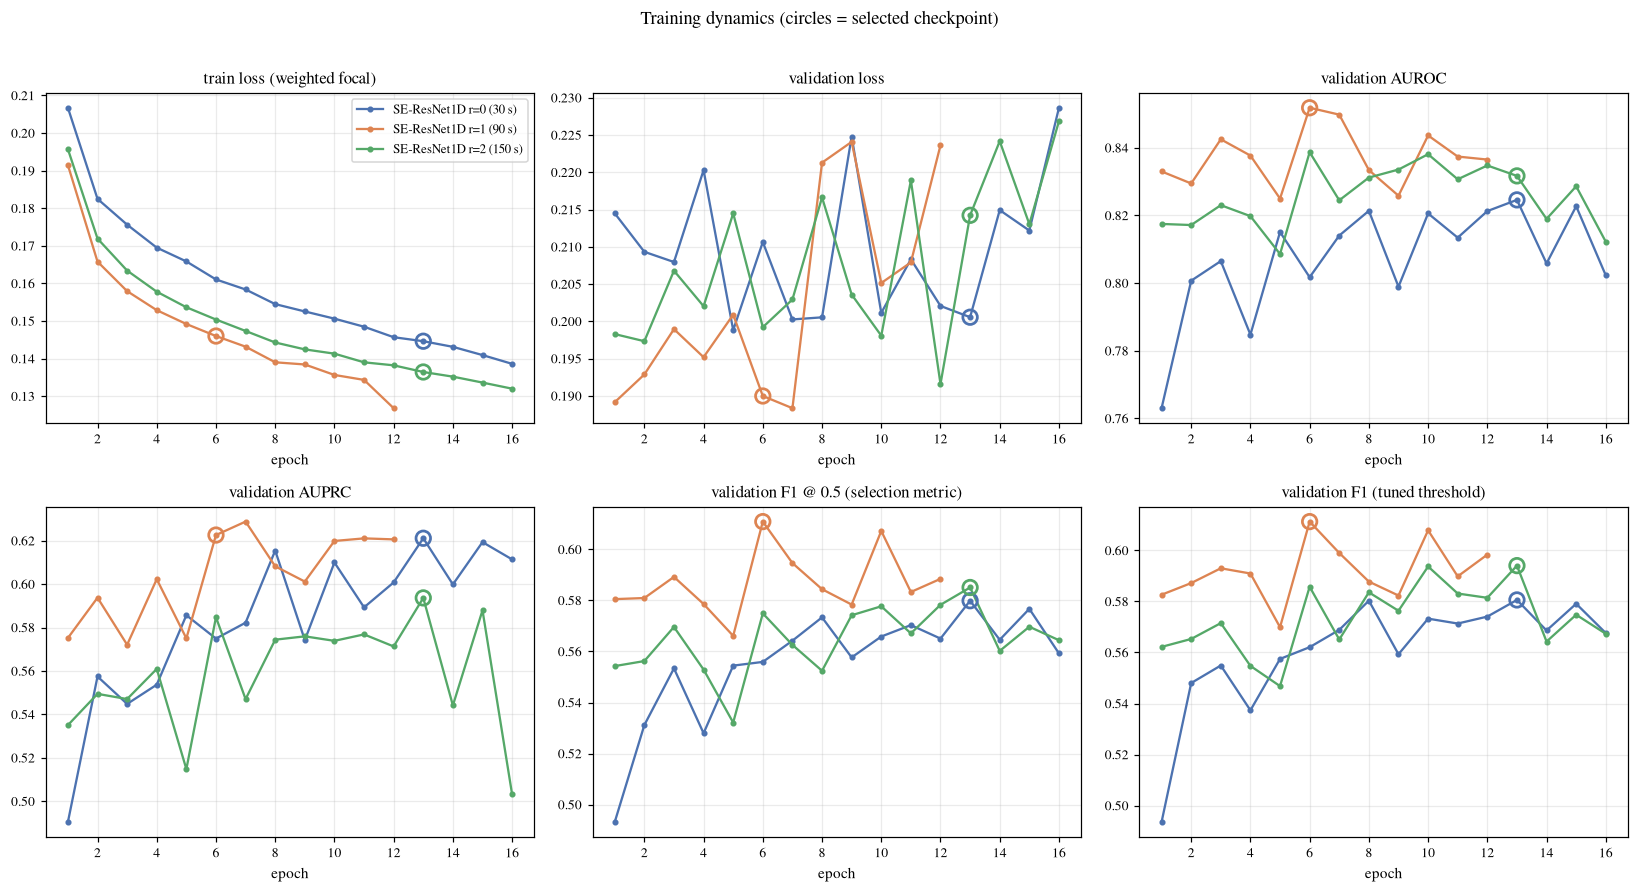

In [16]:
# F01 — training curves
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
panels = [("train_loss", "train loss (weighted focal)"), ("val_loss", "validation loss"),
          ("val_auroc", "validation AUROC"), ("val_auprc", "validation AUPRC"),
          ("val_f1_05", "validation F1 @ 0.5 (selection metric)"),
          ("val_f1_tuned", "validation F1 (tuned threshold)")]
for a, (col, title) in zip(ax.ravel(), panels):
    for r in RADII:
        h = RUNS[r]["history"]
        a.plot(h.epoch, h[col], marker="o", ms=3, color=MODEL_COLOR[r], label=MODEL_LABEL[r])
        if col != "lr":
            be = RUNS[r]["info"]["best_epoch"]
            a.scatter([be], h.loc[h.epoch == be, col], s=90, facecolor="none",
                      edgecolor=MODEL_COLOR[r], lw=1.8, zorder=5)
    a.set_title(title); a.set_xlabel("epoch")
    if col == "lr":
        a.set_yscale("log")
ax[0, 0].legend()
fig.suptitle("Training dynamics (circles = selected checkpoint)", y=1.01)
fig.tight_layout()
savefig(fig, "F01_training_curves")

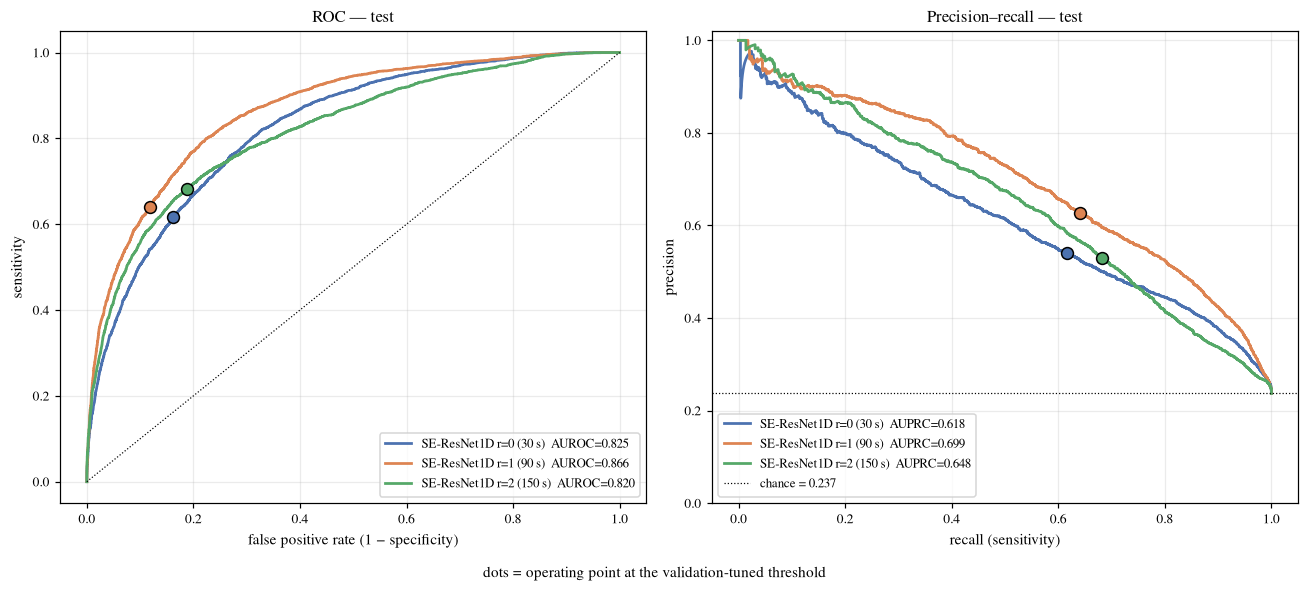

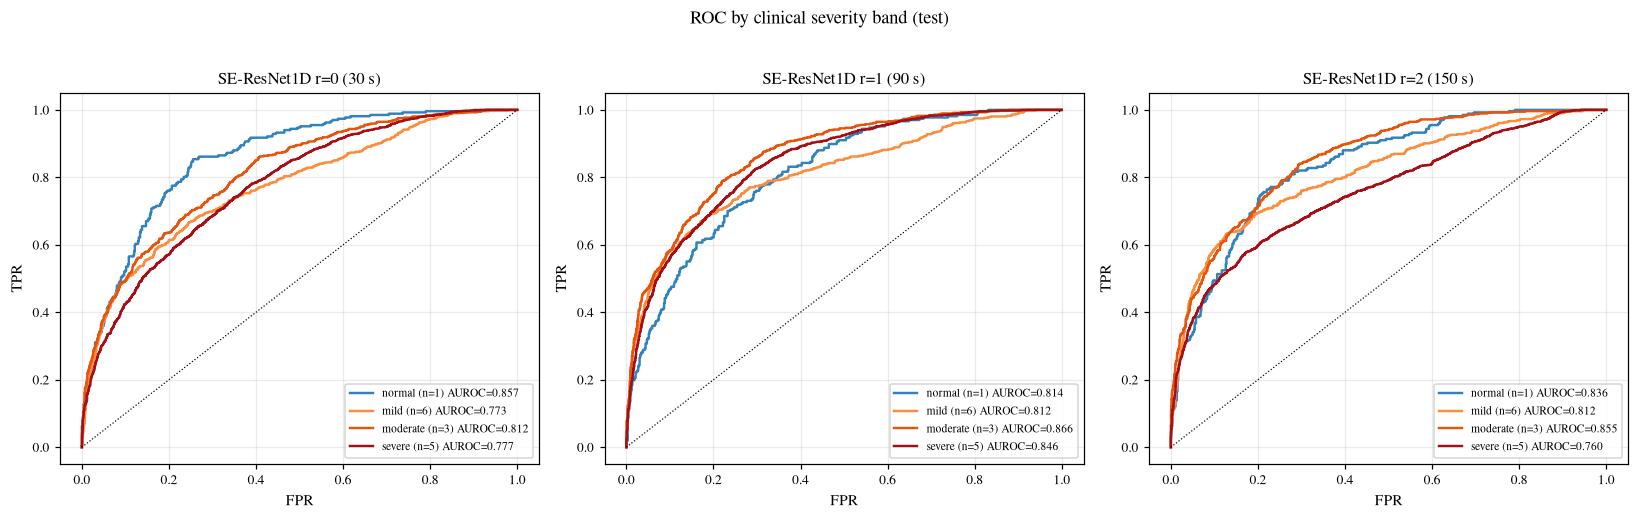

In [17]:
# F02 — ROC and PR curves (test), plus ROC by severity band
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
prev = RUNS[RADII[0]]["test"]["y"].mean()
for r in RADII:
    T = RUNS[r]["test"]
    fpr, tpr, _ = roc_curve(T["y"], T["p"])
    pr_, rc_, _ = precision_recall_curve(T["y"], T["p"])
    ax[0].plot(fpr, tpr, color=MODEL_COLOR[r], lw=1.8,
               label=f"{MODEL_LABEL[r]}  AUROC={safe_auc(T['y'], T['p']):.3f}")
    ax[1].plot(rc_, pr_, color=MODEL_COLOR[r], lw=1.8,
               label=f"{MODEL_LABEL[r]}  AUPRC={safe_ap(T['y'], T['p']):.3f}")
    key, thr = EVAL[r]["var_def"]["raw@tuned"]
    m = binary_metrics(T["y"], (T["p"] >= thr).astype(int))
    ax[0].scatter(1 - m["specificity"], m["sensitivity"], color=MODEL_COLOR[r],
                  edgecolor="k", s=60, zorder=5)
    ax[1].scatter(m["sensitivity"], m["precision"], color=MODEL_COLOR[r],
                  edgecolor="k", s=60, zorder=5)
ax[0].plot([0, 1], [0, 1], "k:", lw=.8)
ax[0].set_xlabel("false positive rate (1 − specificity)"); ax[0].set_ylabel("sensitivity")
ax[0].set_title("ROC — test"); ax[0].legend(loc="lower right")
ax[1].axhline(prev, ls=":", c="k", lw=.8, label=f"chance = {prev:.3f}")
ax[1].set_xlabel("recall (sensitivity)"); ax[1].set_ylabel("precision")
ax[1].set_title("Precision–recall — test"); ax[1].legend(loc="lower left"); ax[1].set_ylim(0, 1.02)
fig.text(0.5, -0.02, "dots = operating point at the validation-tuned threshold", ha="center")
fig.tight_layout()
savefig(fig, "F02_roc_pr_test")

fig, ax = plt.subplots(1, len(RADII), figsize=(5 * len(RADII), 4.6), squeeze=False)
sev_col = dict(zip(SEVERITY_NAMES, ["#3182bd", "#fd8d3c", "#e6550d", "#a50f15"]))
for a, r in zip(ax[0], RADII):
    T = RUNS[r]["test"]
    sev_arr = PATIENTS.set_index("patient").severity.reindex(T["pid"]).values
    for sev in SEVERITY_NAMES:
        m = sev_arr == sev
        if m.sum() and len(np.unique(T["y"][m])) == 2:
            f_, t_, _ = roc_curve(T["y"][m], T["p"][m])
            n_p = len(set(T["pid"][m]))
            a.plot(f_, t_, color=sev_col[sev], lw=1.6,
                   label=f"{sev} (n={n_p}) AUROC={safe_auc(T['y'][m], T['p'][m]):.3f}")
    a.plot([0, 1], [0, 1], "k:", lw=.8)
    a.set_title(MODEL_LABEL[r]); a.set_xlabel("FPR"); a.set_ylabel("TPR")
    a.legend(loc="lower right", fontsize=7.5)
fig.suptitle("ROC by clinical severity band (test)", y=1.02)
fig.tight_layout()
savefig(fig, "F02b_roc_by_severity")

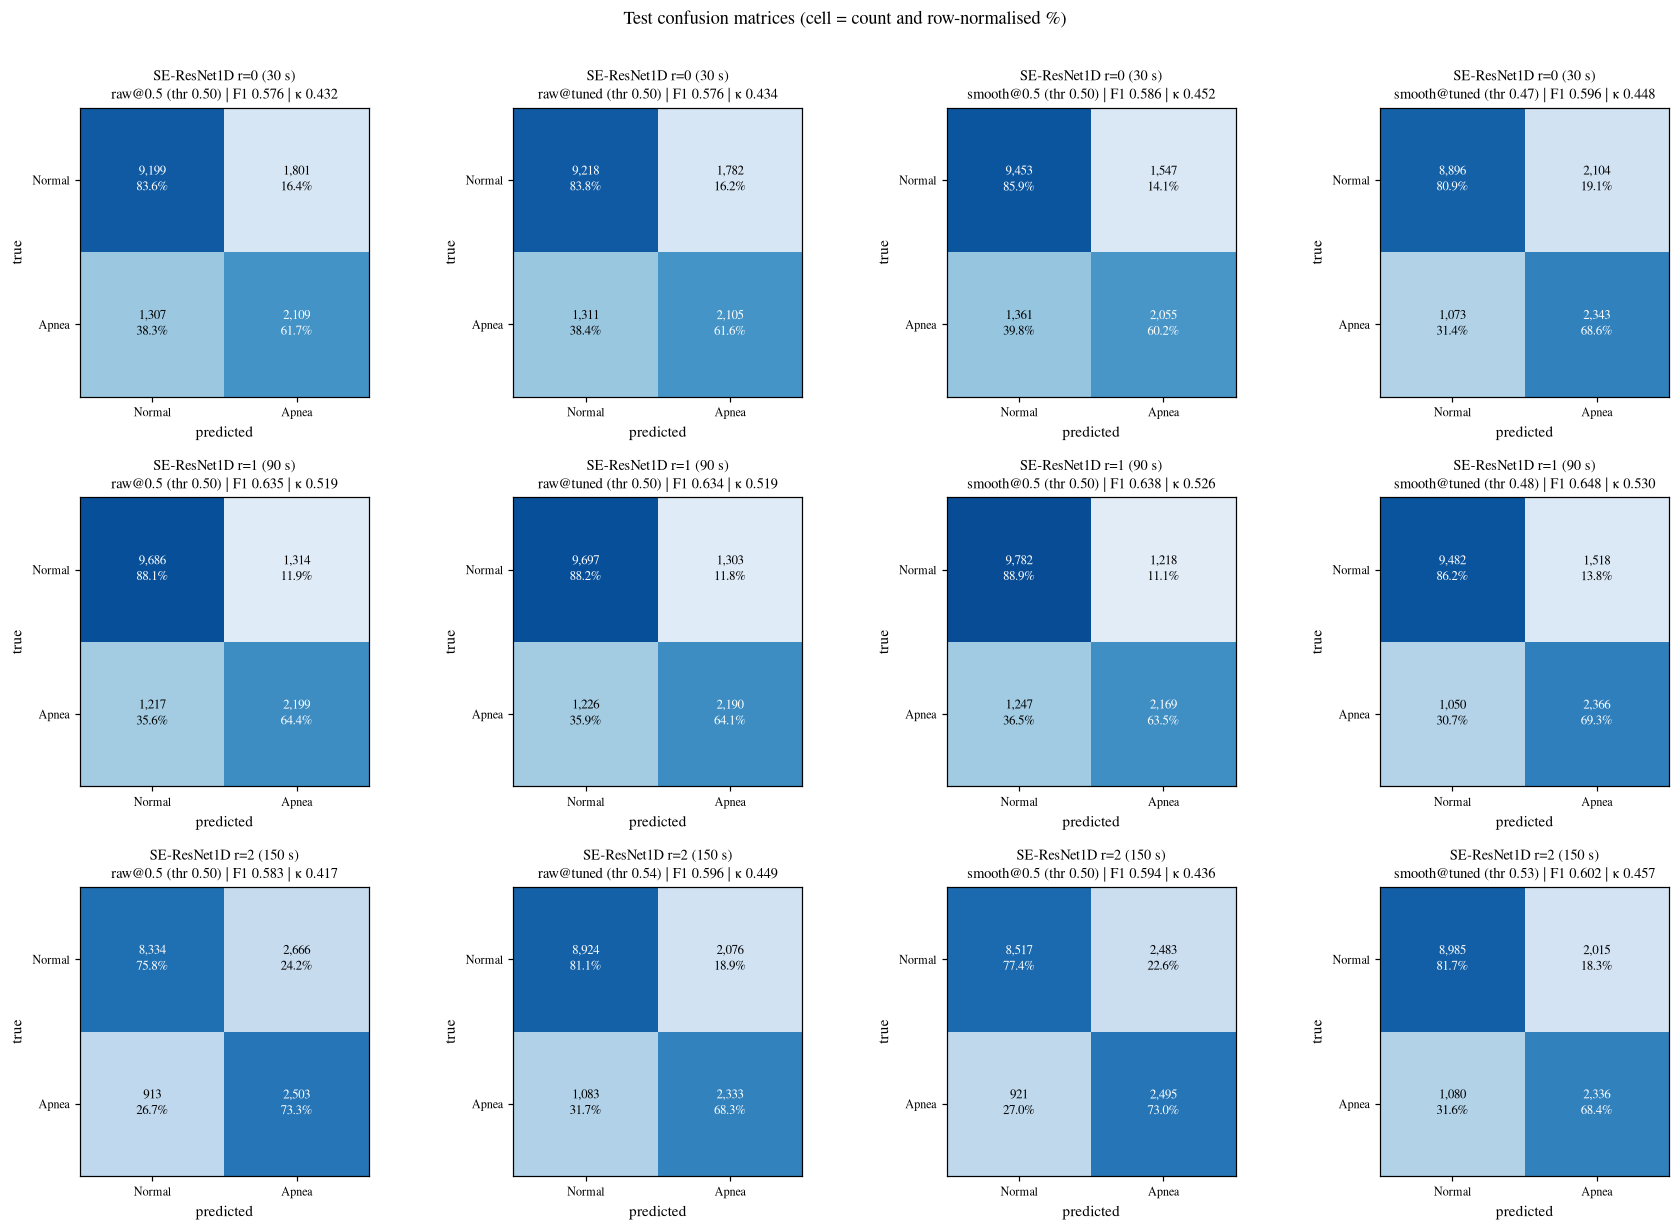

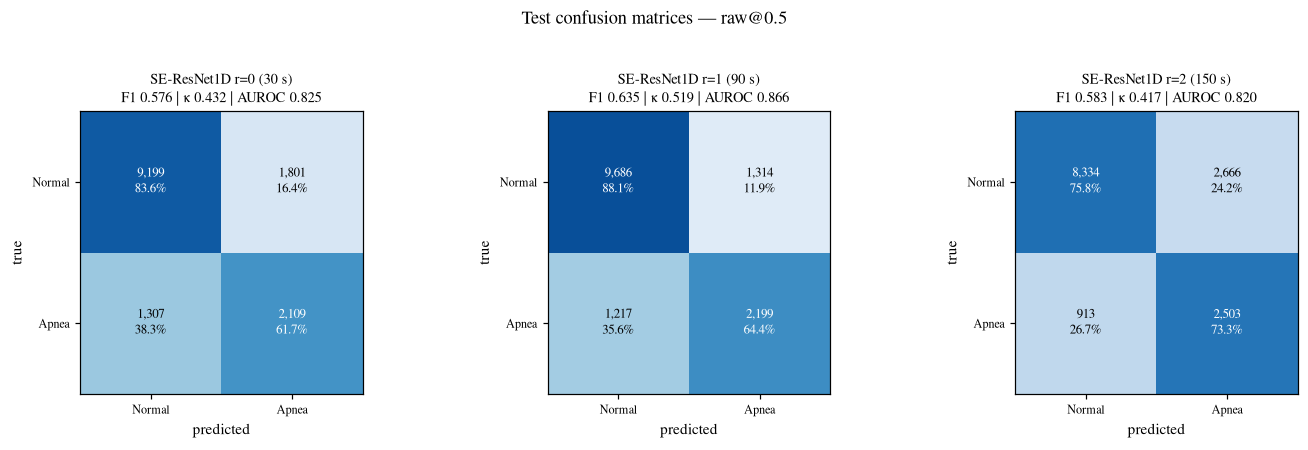

In [18]:
# F03 — confusion matrices: models × decision rules (counts + row %)
def draw_cm(a, cm, title, labels=("Normal", "Apnea"), cmap="Blues"):
    rown = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    a.imshow(rown, cmap=cmap, vmin=0, vmax=1)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            a.text(j, i, f"{cm[i, j]:,}\n{100 * rown[i, j]:.1f}%", ha="center", va="center",
                   fontsize=8.5, color="white" if rown[i, j] > .55 else "black")
    a.set_xticks(range(len(labels))); a.set_xticklabels(labels, fontsize=8)
    a.set_yticks(range(len(labels))); a.set_yticklabels(labels, fontsize=8)
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(title, fontsize=9.5)
    a.grid(False)

fig, ax = plt.subplots(len(RADII), len(VARIANTS), figsize=(4 * len(VARIANTS), 3.7 * len(RADII)),
                       squeeze=False)
for i, r in enumerate(RADII):
    for j, v in enumerate(VARIANTS):
        row = T1[(T1.model == MODEL_LABEL[r]) & (T1.variant == v)].iloc[0]
        draw_cm(ax[i, j], EVAL[r]["cms"][v],
                f"{MODEL_LABEL[r]}\n{v} (thr {row.threshold:.2f}) | F1 {row.f1:.3f} | "
                f"κ {row.cohen_kappa:.3f}")
fig.suptitle("Test confusion matrices (cell = count and row-normalised %)", y=1.005)
fig.tight_layout()
savefig(fig, "F03_confusion_matrices_all")

fig, ax = plt.subplots(1, len(RADII), figsize=(4.3 * len(RADII), 3.9), squeeze=False)
for a, r in zip(ax[0], RADII):
    row = T1[(T1.model == MODEL_LABEL[r]) & (T1.variant == PRIMARY_VARIANT)].iloc[0]
    draw_cm(a, EVAL[r]["cms"][PRIMARY_VARIANT],
            f"{MODEL_LABEL[r]}\nF1 {row.f1:.3f} | κ {row.cohen_kappa:.3f} | AUROC {row.auroc:.3f}")
fig.suptitle(f"Test confusion matrices — {PRIMARY_VARIANT}", y=1.03)
fig.tight_layout()
savefig(fig, "F03b_confusion_matrices_primary")

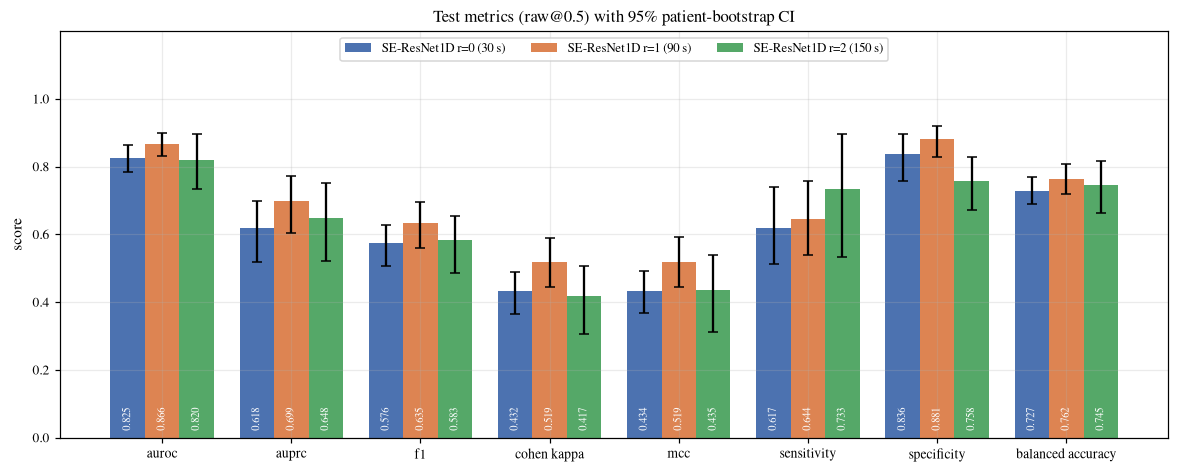

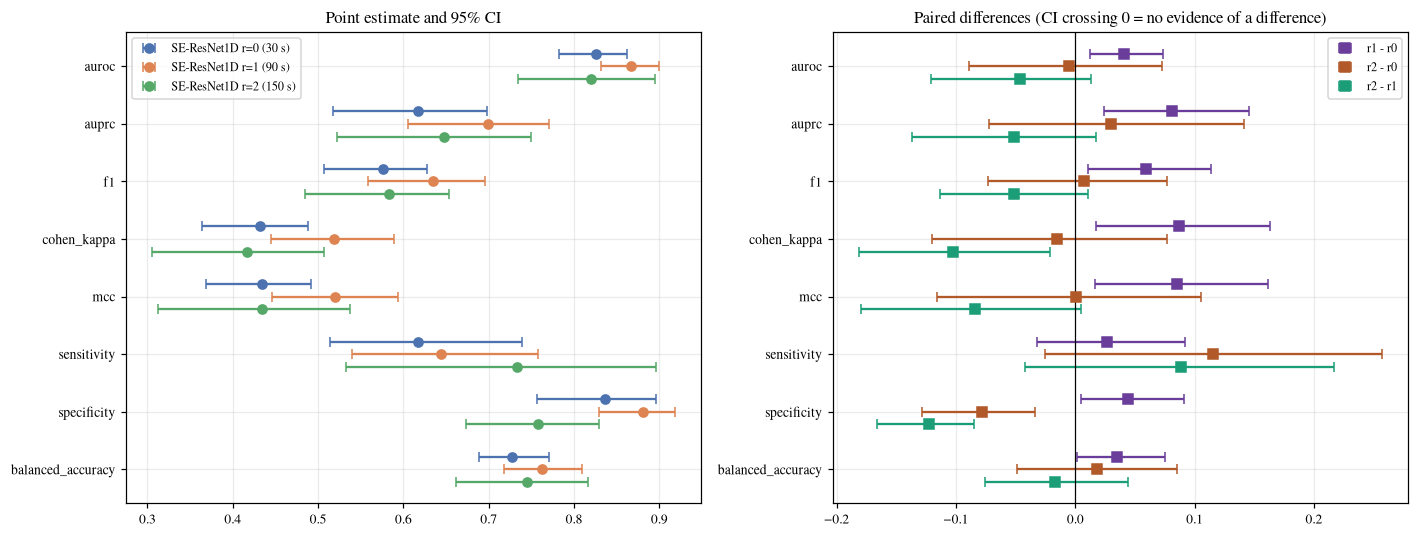

In [19]:
# F04 — headline metric bars with 95% bootstrap CI  +  F05 forest plot
metrics_show = BOOT_METRICS
fig, ax = plt.subplots(figsize=(13, 4.8))
w = 0.8 / len(RADII)
x = np.arange(len(metrics_show))
for k, r in enumerate(RADII):
    c = CI.query("radius==@r").set_index("metric").reindex(metrics_show)
    ax.bar(x + (k - (len(RADII) - 1) / 2) * w, c.value, w, color=MODEL_COLOR[r],
           yerr=[c.value - c.ci_low, c.ci_high - c.value], capsize=3, label=MODEL_LABEL[r])
    for xi, v in zip(x + (k - (len(RADII) - 1) / 2) * w, c.value):
        ax.text(xi, 0.02, f"{v:.3f}", rotation=90, ha="center", va="bottom", fontsize=7,
                color="white")
ax.set_xticks(x); ax.set_xticklabels([m.replace("_", " ") for m in metrics_show])
ax.set_ylim(0, 1.2); ax.set_yticks(np.arange(0, 1.01, .2)); ax.set_ylabel("score")
ax.legend(ncol=3, loc="upper center")
ax.set_title(f"Test metrics ({PRIMARY_VARIANT}) with 95% patient-bootstrap CI")
savefig(fig, "F04_metric_bars_ci")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ypos = np.arange(len(metrics_show))
for k, r in enumerate(RADII):
    c = CI.query("radius==@r").set_index("metric").reindex(metrics_show)
    yy = ypos + (k - 1) * 0.22
    ax[0].errorbar(c.value, yy, xerr=[c.value - c.ci_low, c.ci_high - c.value], fmt="o",
                   color=MODEL_COLOR[r], capsize=3, label=MODEL_LABEL[r])
ax[0].set_yticks(ypos); ax[0].set_yticklabels(metrics_show); ax[0].invert_yaxis()
ax[0].set_title("Point estimate and 95% CI"); ax[0].legend(fontsize=8)
comps = BOOT_DIFF.comparison.unique()
cc = ["#6a3d9a", "#b15928", "#1b9e77"]
for k, cp in enumerate(comps):
    d = BOOT_DIFF.query("comparison==@cp").set_index("metric").reindex(metrics_show)
    yy = ypos + (k - 1) * 0.22
    ax[1].errorbar(d.delta, yy, xerr=[d.delta - d.ci_low, d.ci_high - d.delta], fmt="s",
                   color=cc[k % 3], capsize=3, label=cp)
ax[1].axvline(0, c="k", lw=.8)
ax[1].set_yticks(ypos); ax[1].set_yticklabels(metrics_show); ax[1].invert_yaxis()
ax[1].set_title("Paired differences (CI crossing 0 = no evidence of a difference)")
ax[1].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "F05_forest_ci_and_differences")

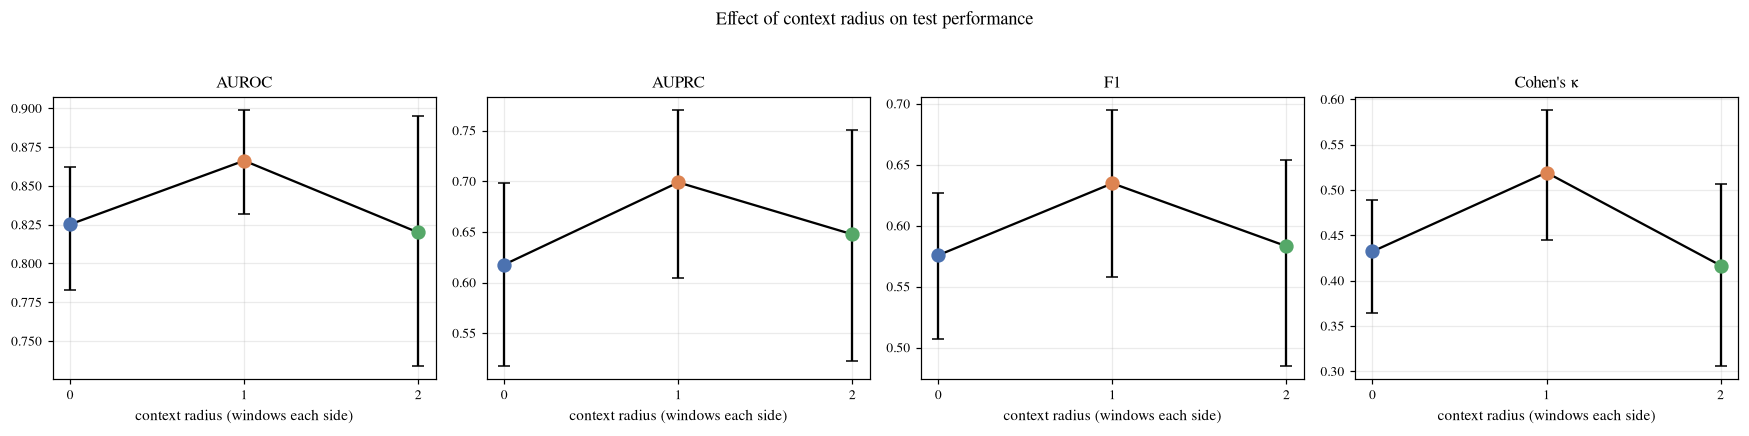

In [20]:
# F06 — metric trend vs context radius
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, mname in zip(ax, ["auroc", "auprc", "f1", "cohen_kappa"]):
    c = CI.query("metric==@mname").sort_values("radius")
    a.errorbar(c.radius, c.value, yerr=[c.value - c.ci_low, c.ci_high - c.value],
               fmt="-o", color="k", capsize=4)
    for _, row in c.iterrows():
        a.scatter(row.radius, row.value, s=70, color=MODEL_COLOR[int(row.radius)], zorder=5)
    a.set_xticks(RADII); a.set_xlabel("context radius (windows each side)")
    a.set_title(mname.replace("_", " ").upper() if mname != "cohen_kappa" else "Cohen's κ")
fig.suptitle("Effect of context radius on test performance", y=1.03)
fig.tight_layout()
savefig(fig, "F06_trend_vs_radius")

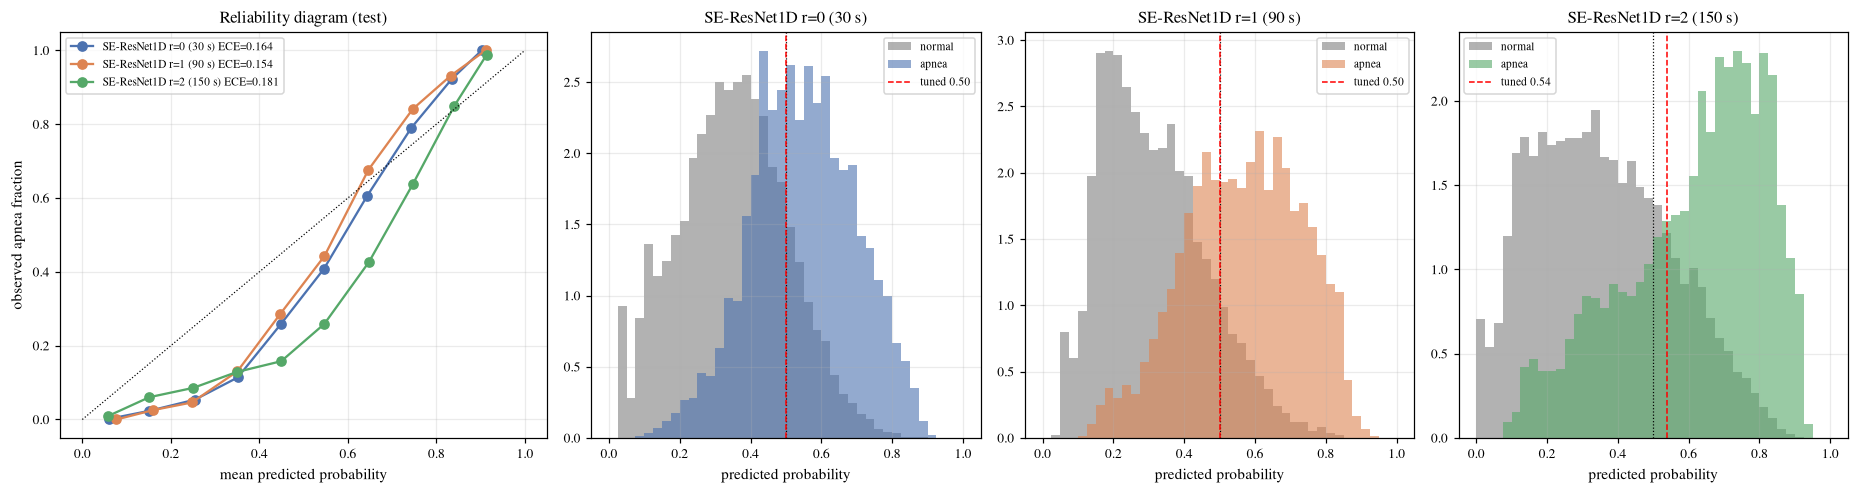

In [21]:
# F07 — calibration: reliability diagrams + class-conditional probability histograms
fig = plt.figure(figsize=(5 + 4 * len(RADII), 4.6))
gs = fig.add_gridspec(1, 1 + len(RADII), width_ratios=[1.25] + [1] * len(RADII))
a0 = fig.add_subplot(gs[0])
edges = np.linspace(0, 1, N_CALIB_BINS + 1)
for r in RADII:
    T = RUNS[r]["test"]
    b = np.clip(np.digitize(T["p"], edges[1:-1]), 0, N_CALIB_BINS - 1)
    mp = [T["p"][b == i].mean() if (b == i).any() else np.nan for i in range(N_CALIB_BINS)]
    fr = [T["y"][b == i].mean() if (b == i).any() else np.nan for i in range(N_CALIB_BINS)]
    ece = expected_calibration_error(T["y"].astype(int), T["p"])
    a0.plot(mp, fr, "-o", color=MODEL_COLOR[r], label=f"{MODEL_LABEL[r]} ECE={ece:.3f}")
a0.plot([0, 1], [0, 1], "k:", lw=.8)
a0.set_xlabel("mean predicted probability"); a0.set_ylabel("observed apnea fraction")
a0.set_title("Reliability diagram (test)"); a0.legend(fontsize=7.5)
for k, r in enumerate(RADII):
    a = fig.add_subplot(gs[k + 1])
    T = RUNS[r]["test"]
    a.hist(T["p"][T["y"] == 0], bins=40, range=(0, 1), alpha=.6, density=True,
           color="#7f7f7f", label="normal")
    a.hist(T["p"][T["y"] == 1], bins=40, range=(0, 1), alpha=.6, density=True,
           color=MODEL_COLOR[r], label="apnea")
    a.axvline(0.5, c="k", ls=":", lw=.8)
    a.axvline(EVAL[r]["thr_raw"], c="r", ls="--", lw=1, label=f"tuned {EVAL[r]['thr_raw']:.2f}")
    a.set_title(MODEL_LABEL[r]); a.set_xlabel("predicted probability"); a.legend(fontsize=7.5)
fig.tight_layout()
savefig(fig, "F07_calibration_and_score_distributions")

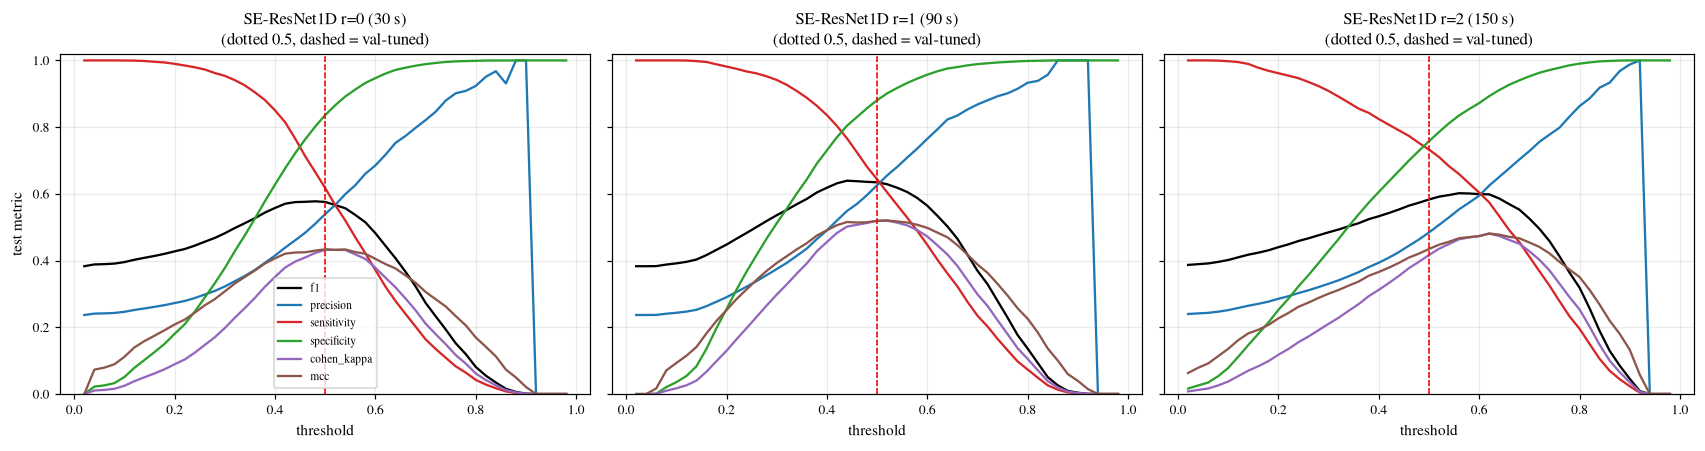

In [22]:
# F08 — threshold sweeps
fig, ax = plt.subplots(1, len(RADII), figsize=(5.2 * len(RADII), 4.2), sharey=True, squeeze=False)
for a, r in zip(ax[0], RADII):
    sw = EVAL[r]["sweep"]
    for col, c in [("f1", "k"), ("precision", "#1f77b4"), ("sensitivity", "#d62728"),
                   ("specificity", "#2ca02c"), ("cohen_kappa", "#9467bd"), ("mcc", "#8c564b")]:
        a.plot(sw.threshold, sw[col], color=c, lw=1.5, label=col)
    a.axvline(0.5, c="gray", ls=":", lw=1)
    a.axvline(EVAL[r]["var_def"][PRIMARY_VARIANT][1], c="r", ls="--", lw=1)
    a.set_title(f"{MODEL_LABEL[r]}\n(dotted 0.5, dashed = val-tuned)")
    a.set_xlabel("threshold"); a.set_ylim(0, 1.02)
ax[0, 0].set_ylabel("test metric"); ax[0, 0].legend(fontsize=7.5, loc="lower center")
fig.tight_layout()
savefig(fig, "F08_threshold_sweep")

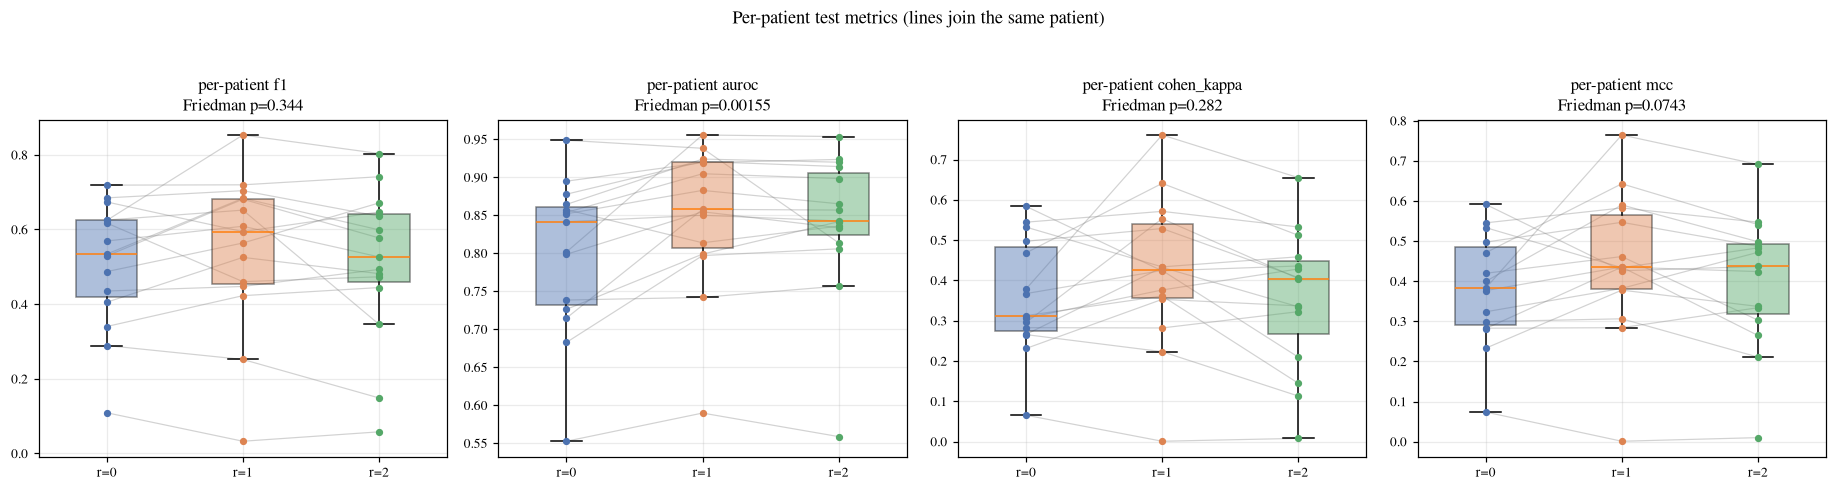

In [23]:
# F09 — per-patient distributions with paired lines
mset = ["f1", "auroc", "cohen_kappa", "mcc"]
fig, ax = plt.subplots(1, len(mset), figsize=(4.2 * len(mset), 4.3))
for a, mname in zip(ax, mset):
    wide = PP.pivot(index="patient", columns="radius", values=mname)[RADII]
    for _, row in wide.iterrows():
        a.plot(range(len(RADII)), row.values, c="gray", alpha=.35, lw=.8)
    bp = a.boxplot([wide[r].dropna() for r in RADII], positions=range(len(RADII)),
                   widths=.45, patch_artist=True, showfliers=False)
    for patch, r in zip(bp["boxes"], RADII):
        patch.set_facecolor(MODEL_COLOR[r]); patch.set_alpha(.45)
    for k, r in enumerate(RADII):
        a.scatter(np.full(len(wide), k), wide[r], s=14, color=MODEL_COLOR[r], zorder=4)
    p_row = STATS[(STATS.metric == mname) & STATS.test.str.startswith("Friedman")]
    ptxt = f"Friedman p={p_row.p.iloc[0]:.3g}" if len(p_row) else ""
    a.set_xticks(range(len(RADII))); a.set_xticklabels([f"r={r}" for r in RADII])
    a.set_title(f"per-patient {mname}\n{ptxt}")
fig.suptitle("Per-patient test metrics (lines join the same patient)", y=1.03)
fig.tight_layout()
savefig(fig, "F09_per_patient_paired")

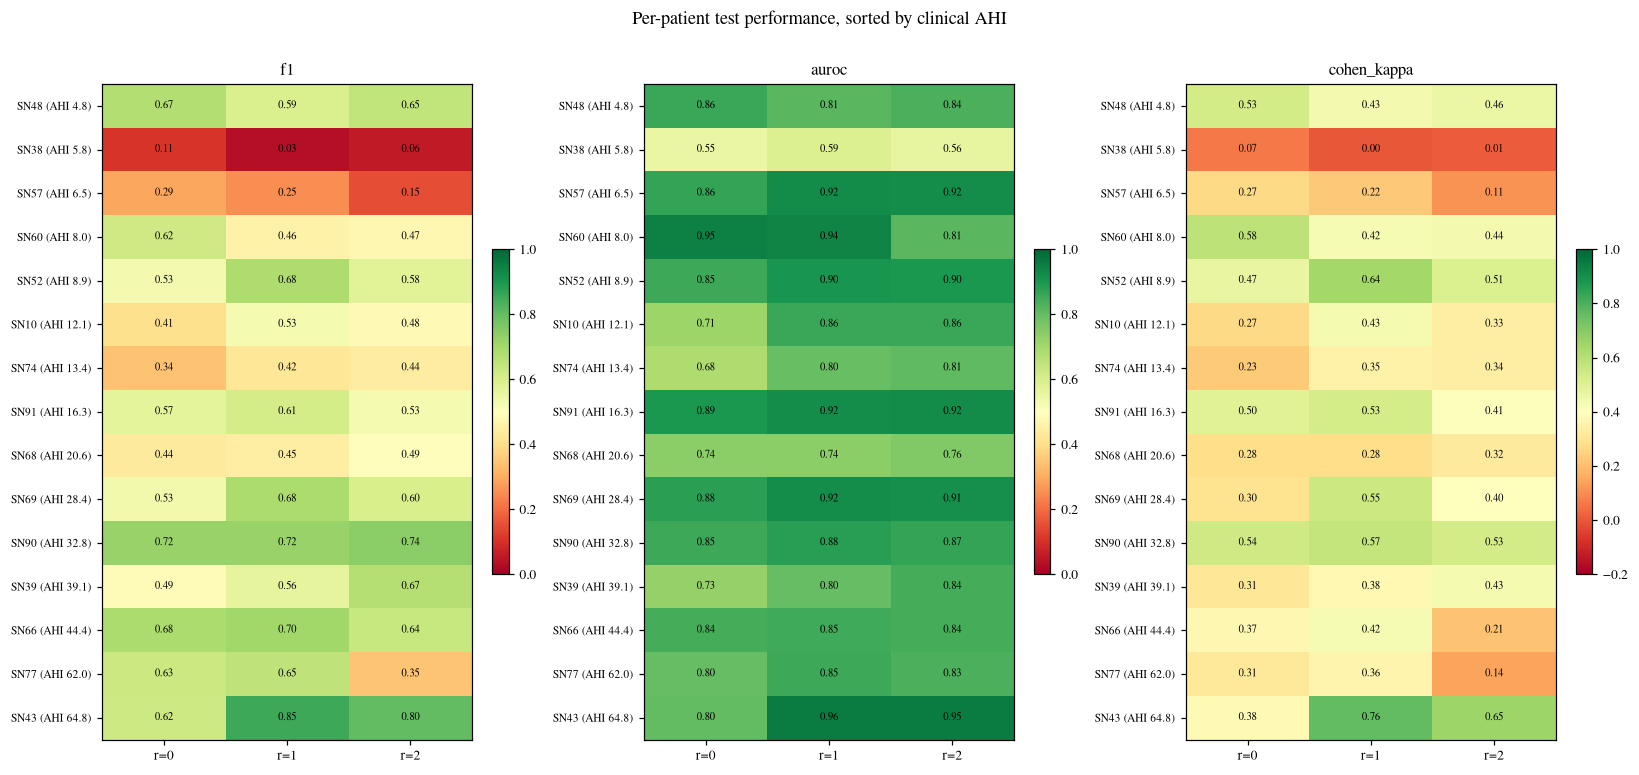

In [24]:
# F10 — per-patient heatmaps (patients sorted by clinical AHI)
order_p = (PP.drop_duplicates("patient").sort_values("strat_ahi").patient.tolist())
fig, ax = plt.subplots(1, 3, figsize=(15, 0.32 * len(order_p) + 2.2))
for a, mname in zip(ax, ["f1", "auroc", "cohen_kappa"]):
    H = PP.pivot(index="patient", columns="radius", values=mname).reindex(order_p)[RADII]
    im = a.imshow(H.values, aspect="auto", cmap="RdYlGn", vmin=0 if mname != "cohen_kappa" else -.2,
                  vmax=1)
    for i in range(H.shape[0]):
        for j in range(H.shape[1]):
            v = H.values[i, j]
            if np.isfinite(v):
                a.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
    ahi_lab = PATIENTS.set_index("patient").strat_ahi.reindex(order_p)
    a.set_yticks(range(len(order_p)))
    a.set_yticklabels([f"{p} (AHI {v:.1f})" for p, v in ahi_lab.items()], fontsize=7.5)
    a.set_xticks(range(len(RADII))); a.set_xticklabels([f"r={r}" for r in RADII])
    a.set_title(mname); a.grid(False)
    fig.colorbar(im, ax=a, fraction=.04)
fig.suptitle("Per-patient test performance, sorted by clinical AHI", y=1.0)
fig.tight_layout()
savefig(fig, "F10_per_patient_heatmap")

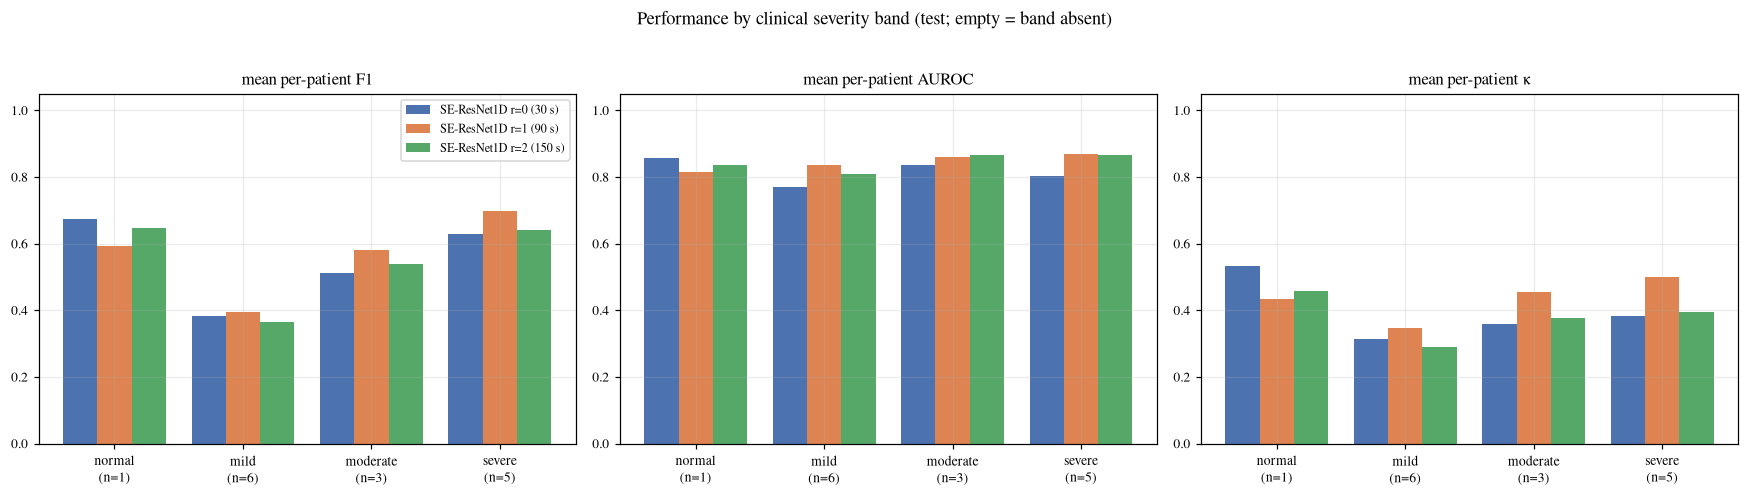

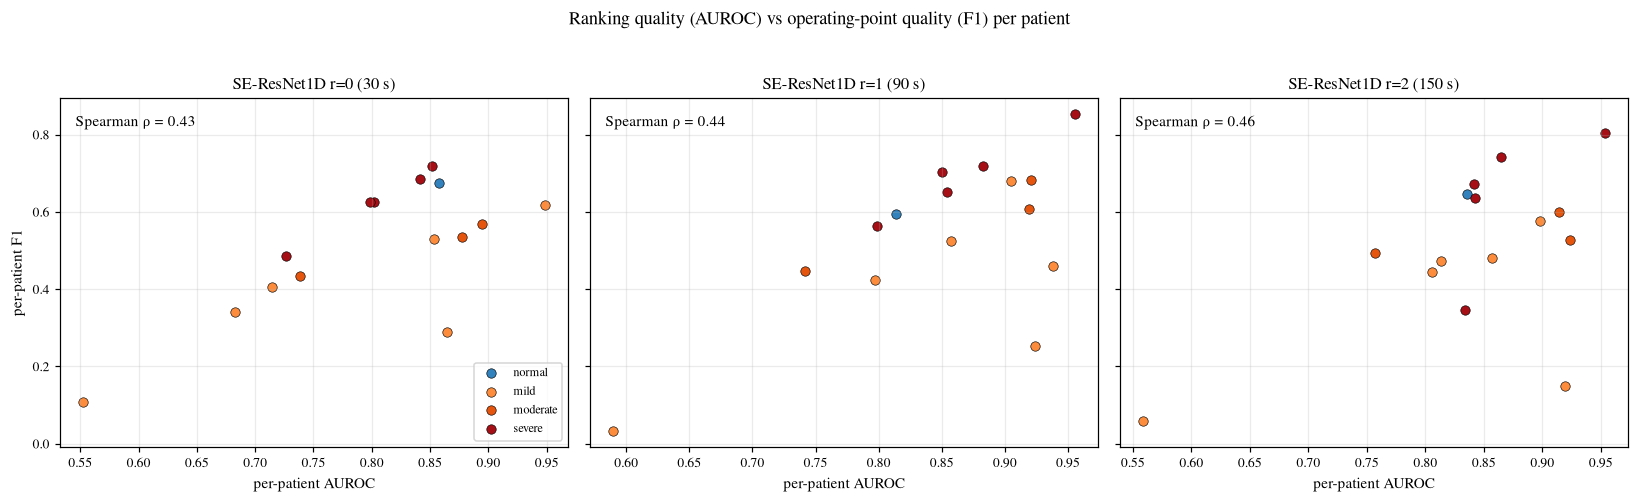

In [25]:
# F11 — severity-stratified performance  +  F12 AUROC-vs-F1 operating-point view
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
xs = np.arange(len(SEVERITY_NAMES))
w = 0.8 / len(RADII)
for a, col, title in zip(ax, ["mean_f1", "mean_auroc", "mean_kappa"],
                         ["mean per-patient F1", "mean per-patient AUROC", "mean per-patient κ"]):
    for k, r in enumerate(RADII):
        s = STR[STR.model == MODEL_LABEL[r]].set_index("severity").reindex(SEVERITY_NAMES)
        a.bar(xs + (k - (len(RADII) - 1) / 2) * w, s[col], w, color=MODEL_COLOR[r],
              label=MODEL_LABEL[r])
    n_lab = STR[STR.model == MODEL_LABEL[RADII[0]]].set_index("severity") \
        .reindex(SEVERITY_NAMES).n_patients.fillna(0).astype(int)
    a.set_xticks(xs); a.set_xticklabels([f"{s}\n(n={n})" for s, n in n_lab.items()])
    a.set_ylim(0, 1.05); a.set_title(title)
ax[0].legend(fontsize=8)
fig.suptitle("Performance by clinical severity band (test; empty = band absent)", y=1.02)
fig.tight_layout()
savefig(fig, "F11_severity_stratified")

fig, ax = plt.subplots(1, len(RADII), figsize=(5 * len(RADII), 4.4), sharey=True, squeeze=False)
for a, r in zip(ax[0], RADII):
    d = PP.query("radius==@r")
    for sev in SEVERITY_NAMES:
        m = d.severity == sev
        a.scatter(d.auroc[m], d.f1[m], s=38, color=sev_col[sev], edgecolor="k", lw=.4, label=sev)
    ok_ = d[["auroc", "f1"]].dropna()
    if len(ok_) > 2:
        rr = stats.spearmanr(ok_.auroc, ok_.f1)[0]
        a.text(.03, .95, f"Spearman ρ = {rr:.2f}", transform=a.transAxes, va="top")
    a.set_xlabel("per-patient AUROC"); a.set_title(MODEL_LABEL[r])
ax[0, 0].set_ylabel("per-patient F1"); ax[0, 0].legend(fontsize=8, loc="lower right")
fig.suptitle("Ranking quality (AUROC) vs operating-point quality (F1) per patient", y=1.03)
fig.tight_layout()
savefig(fig, "F12_auroc_vs_f1_per_patient")

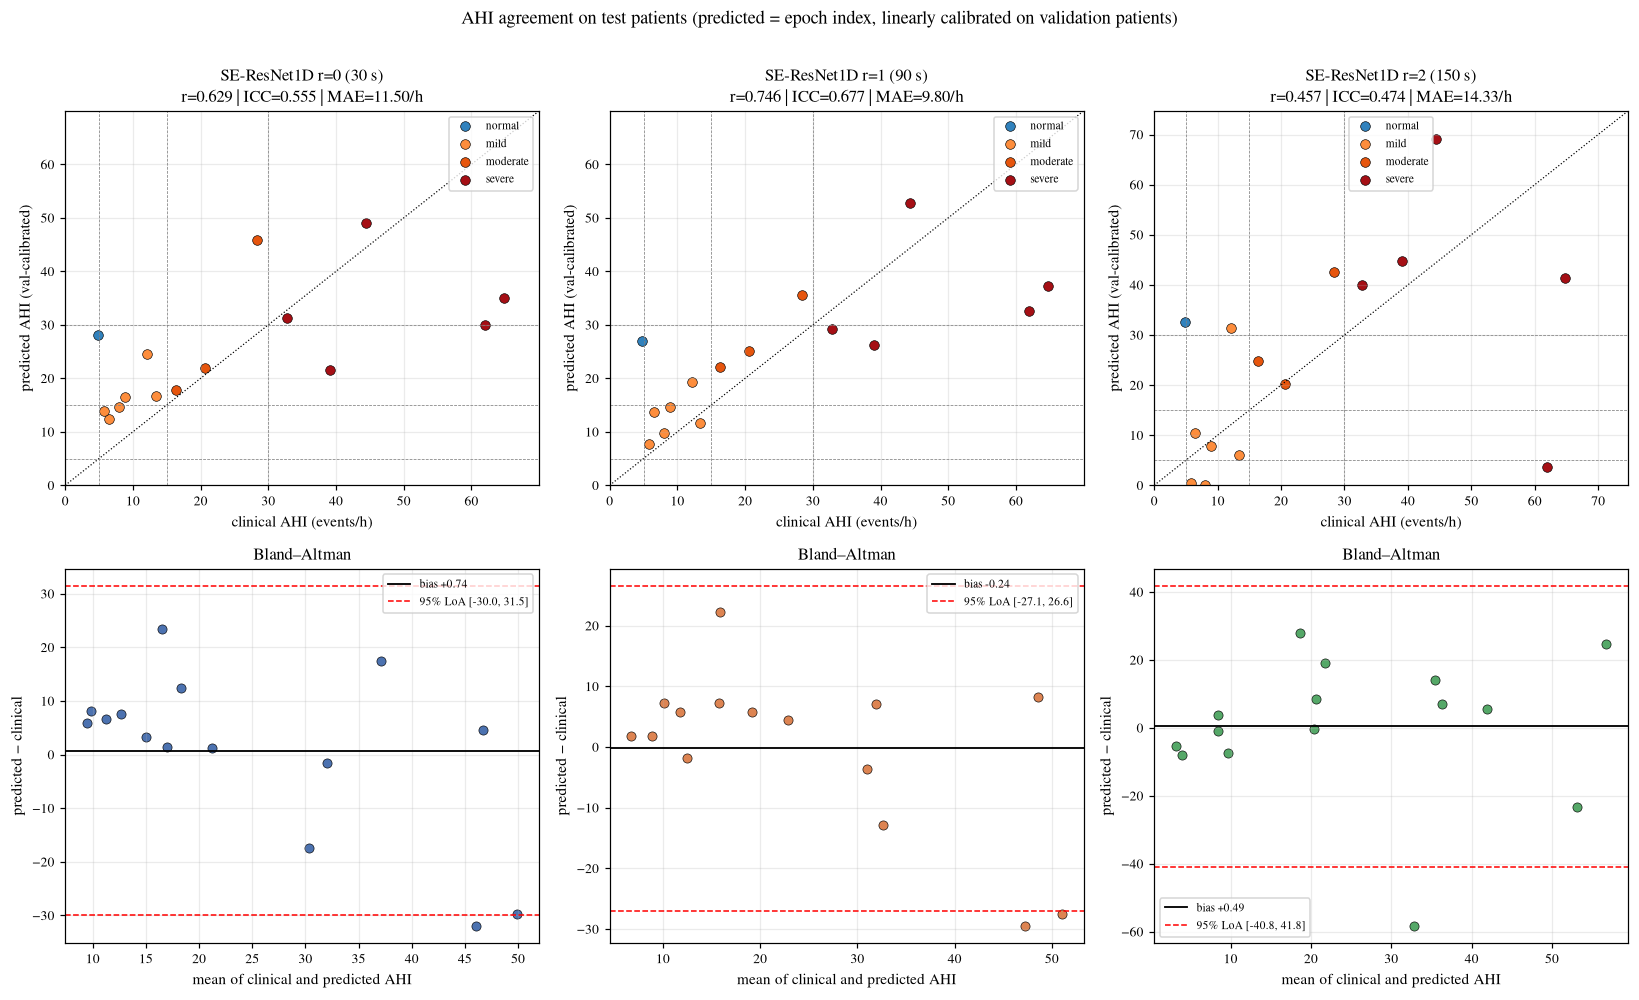

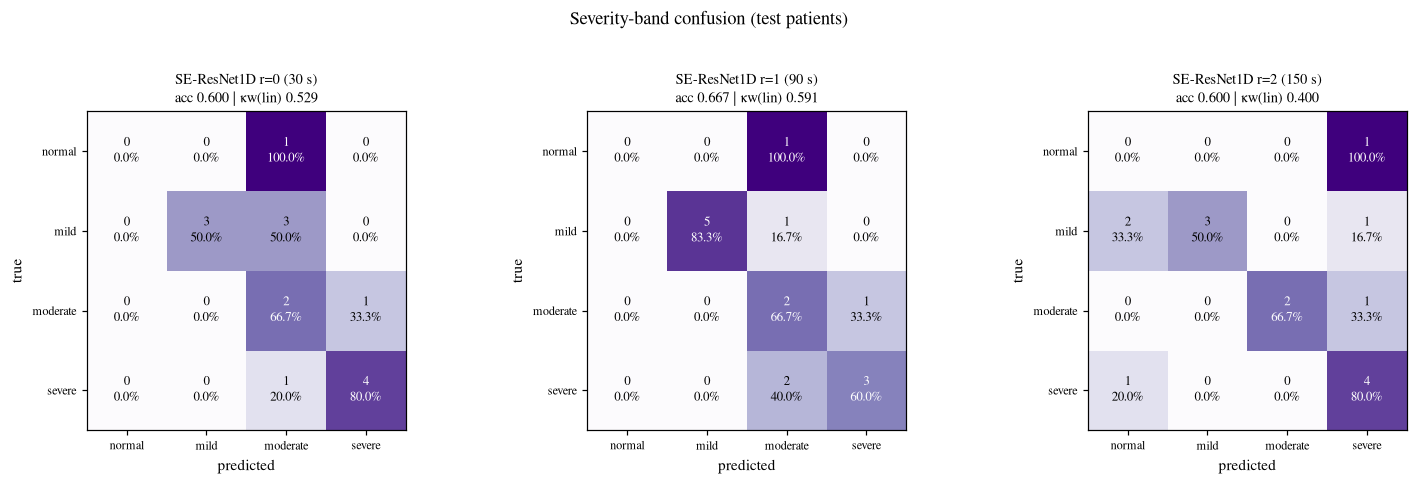

In [26]:
# F13 — AHI agreement: scatter + Bland–Altman ; F14 — severity confusion
fig, ax = plt.subplots(2, len(RADII), figsize=(5 * len(RADII), 9), squeeze=False)
for k, r in enumerate(RADII):
    d = EVAL[r]["pp_test"].dropna(subset=["clinical_ahi"])
    a = ax[0, k]
    lim = max(d.clinical_ahi.max(), d.pred_ahi_calibrated.max(), 1) * 1.08
    for sev in SEVERITY_NAMES:
        m = d.severity == sev
        a.scatter(d.clinical_ahi[m], d.pred_ahi_calibrated[m], s=40, color=sev_col[sev],
                  edgecolor="k", lw=.4, label=sev)
    a.plot([0, lim], [0, lim], "k:", lw=.8)
    for cut in AHI_BINS:
        a.axvline(cut, c="gray", lw=.5, ls="--"); a.axhline(cut, c="gray", lw=.5, ls="--")
    ag = EVAL[r]["ahi"].iloc[0]
    a.set_title(f"{MODEL_LABEL[r]}\nr={ag.pearson_r:.3f} | ICC={ag.icc_a1:.3f} | MAE={ag.mae:.2f}/h")
    a.set_xlabel("clinical AHI (events/h)"); a.set_ylabel("predicted AHI (val-calibrated)")
    a.set_xlim(0, lim); a.set_ylim(0, lim); a.legend(fontsize=7.5)
    b = ax[1, k]
    mean_ = (d.clinical_ahi + d.pred_ahi_calibrated) / 2
    diff_ = d.pred_ahi_calibrated - d.clinical_ahi
    b.scatter(mean_, diff_, s=36, color=MODEL_COLOR[r], edgecolor="k", lw=.4)
    b.axhline(ag.bias, c="k", lw=1.2, label=f"bias {ag.bias:+.2f}")
    b.axhline(ag.loa_low, c="r", ls="--", lw=1, label=f"95% LoA [{ag.loa_low:.1f}, {ag.loa_high:.1f}]")
    b.axhline(ag.loa_high, c="r", ls="--", lw=1)
    b.set_xlabel("mean of clinical and predicted AHI"); b.set_ylabel("predicted − clinical")
    b.set_title("Bland–Altman"); b.legend(fontsize=7.5)
fig.suptitle(f"AHI agreement on test patients (predicted = {AHI_PRED_INDEX} index, "
             "linearly calibrated on validation patients)", y=1.005)
fig.tight_layout()
savefig(fig, "F13_ahi_scatter_bland_altman")

fig, ax = plt.subplots(1, len(RADII), figsize=(4.6 * len(RADII), 4.2), squeeze=False)
for a, r in zip(ax[0], RADII):
    s = SEV[(SEV.model == MODEL_LABEL[r]) & (SEV.comparison == "calibrated pred vs clinical")].iloc[0]
    draw_cm(a, EVAL[r]["sev_cms"]["calibrated pred vs clinical"],
            f"{MODEL_LABEL[r]}\nacc {s.accuracy:.3f} | κw(lin) {s.kappa_linear:.3f}",
            labels=SEVERITY_NAMES, cmap="Purples")
fig.suptitle("Severity-band confusion (test patients)", y=1.03)
fig.tight_layout()
savefig(fig, "F14_severity_confusion")

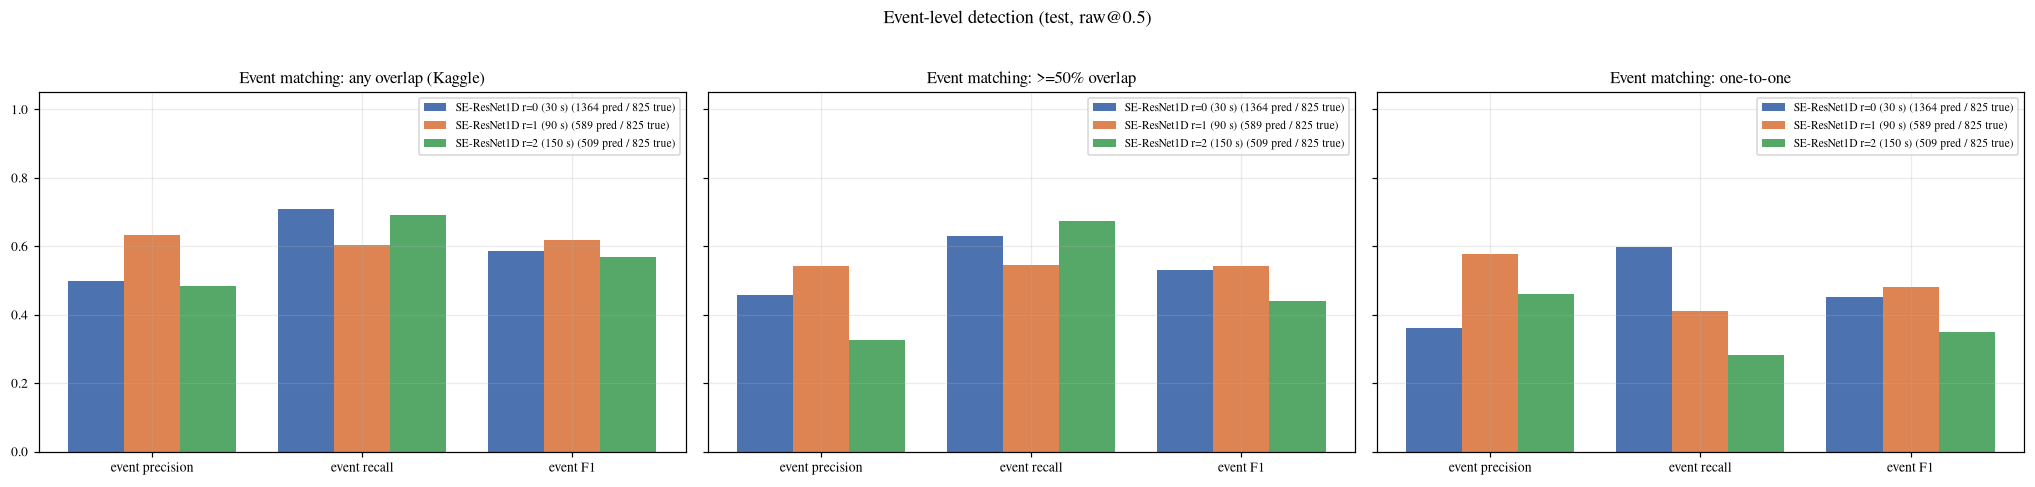

In [27]:
# F15 — event-level detection
fig, ax = plt.subplots(1, len(MATCHINGS), figsize=(6.2 * len(MATCHINGS), 4.3), sharey=True)
for a, (match, _) in zip(ax, MATCHINGS):
    d = EVT[(EVT.variant == PRIMARY_VARIANT) & (EVT.matching == match)]
    xs = np.arange(3)
    for k, r in enumerate(RADII):
        row = d.query("radius==@r").iloc[0]
        vals = [row.event_precision, row.event_recall, row.event_f1]
        a.bar(xs + (k - (len(RADII) - 1) / 2) * w, vals, w, color=MODEL_COLOR[r],
              label=f"{MODEL_LABEL[r]} ({row.pred_events} pred / {row.true_events} true)")
    a.set_xticks(xs); a.set_xticklabels(["event precision", "event recall", "event F1"])
    a.set_title(f"Event matching: {match}"); a.set_ylim(0, 1.05); a.legend(fontsize=7.5)
fig.suptitle(f"Event-level detection (test, {PRIMARY_VARIANT})", y=1.02)
fig.tight_layout()
savefig(fig, "F15_event_level")

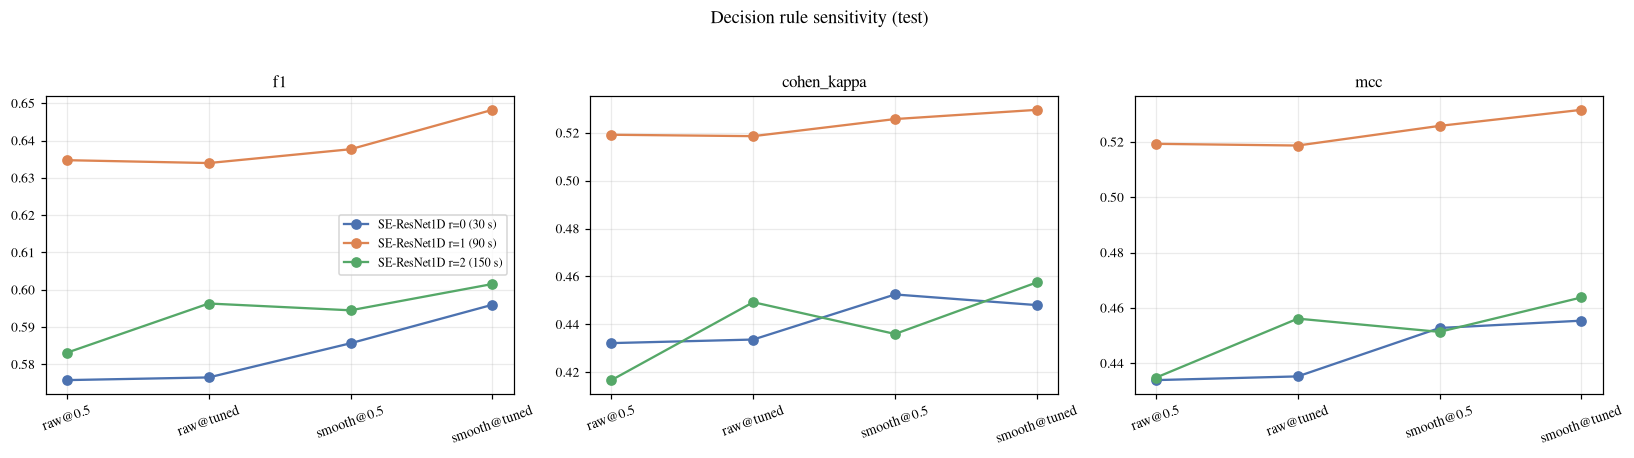

In [28]:
# F16 — effect of decision rule (threshold / smoothing) on each model
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["f1", "cohen_kappa", "mcc"]):
    for r in RADII:
        d = T1[T1.model == MODEL_LABEL[r]].set_index("variant").reindex(VARIANTS)
        a.plot(VARIANTS, d[col], "-o", color=MODEL_COLOR[r], label=MODEL_LABEL[r])
    a.set_title(col); a.tick_params(axis="x", rotation=20)
ax[0].legend(fontsize=8)
fig.suptitle("Decision rule sensitivity (test)", y=1.03)
fig.tight_layout()
savefig(fig, "F16_decision_rule_effect")

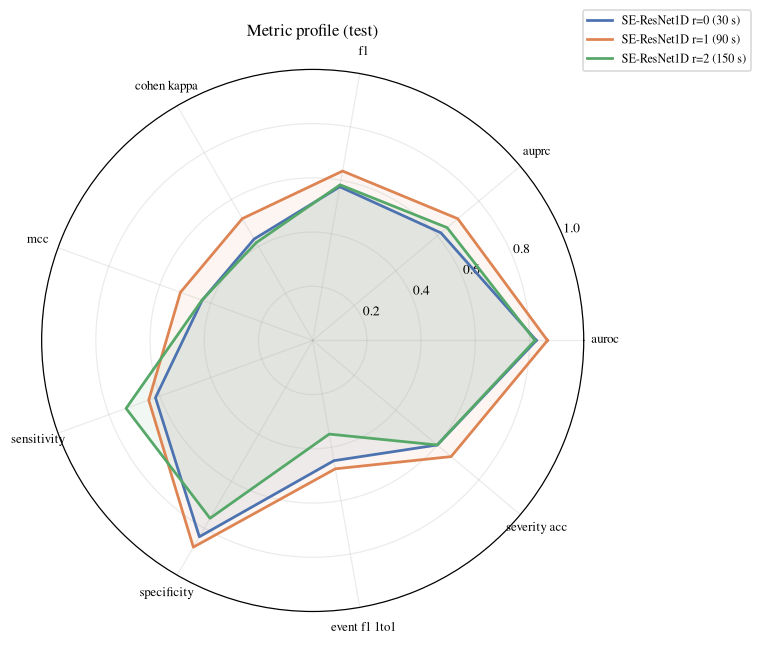

In [29]:
# F17 — radar chart of the headline profile
radar_cols = ["auroc", "auprc", "f1", "cohen_kappa", "mcc", "sensitivity", "specificity",
              "event_f1_1to1", "severity_acc"]
angles = np.linspace(0, 2 * np.pi, len(radar_cols), endpoint=False).tolist()
angles += angles[:1]
fig = plt.figure(figsize=(6.4, 6.4))
a = fig.add_subplot(111, polar=True)
for r, (_, row) in zip(RADII, HEAD.iterrows()):
    vals = [float(np.nan_to_num(row[c])) for c in radar_cols]
    vals += vals[:1]
    a.plot(angles, vals, color=MODEL_COLOR[r], lw=1.8, label=MODEL_LABEL[r])
    a.fill(angles, vals, color=MODEL_COLOR[r], alpha=.08)
a.set_xticks(angles[:-1]); a.set_xticklabels([c.replace("_", " ") for c in radar_cols], fontsize=8.5)
a.set_ylim(0, 1)
a.legend(loc="upper right", bbox_to_anchor=(1.32, 1.12), fontsize=8)
a.set_title("Metric profile (test)", pad=22)
savefig(fig, "F17_radar")

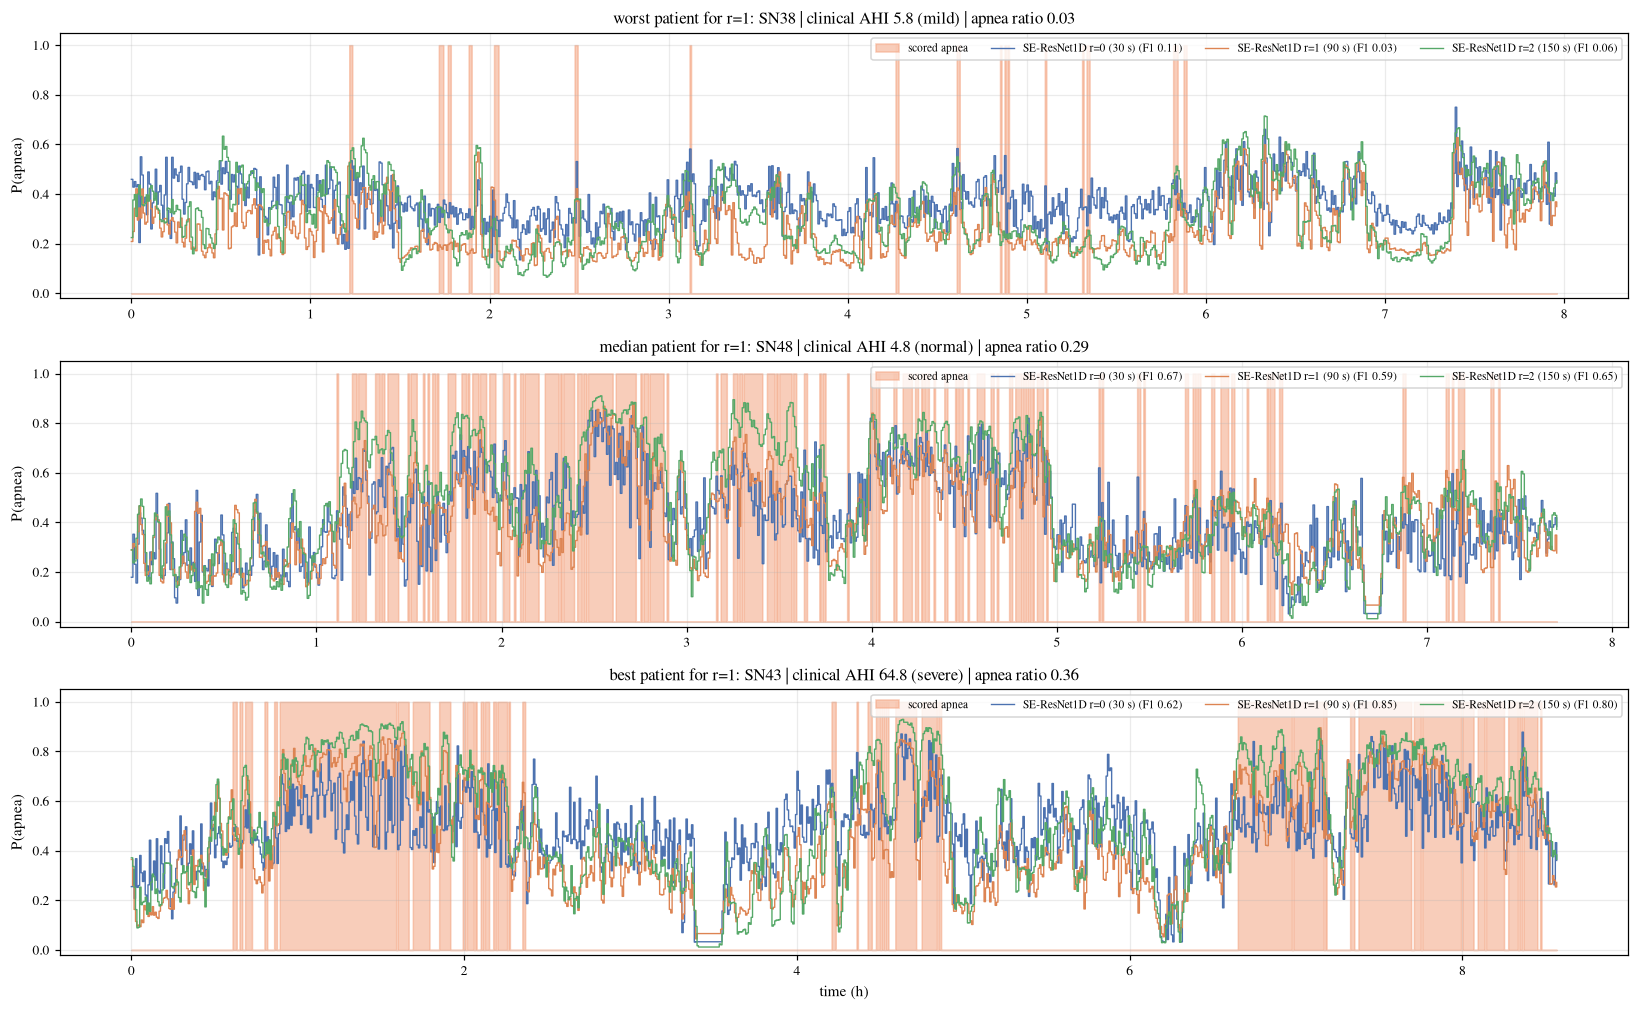

In [30]:
# F18 — probability timelines for the best / median / worst test patient
ref_r = RADII[len(RADII) // 2]
pp_ref = EVAL[ref_r]["pp_test"].dropna(subset=["f1"]).sort_values("f1")
picks = [("worst", pp_ref.iloc[0].patient), ("median", pp_ref.iloc[len(pp_ref) // 2].patient),
         ("best", pp_ref.iloc[-1].patient)]
fig, ax = plt.subplots(len(picks), 1, figsize=(15, 3.1 * len(picks)))
for a, (tag, pid) in zip(np.atleast_1d(ax), picks):
    T0 = RUNS[RADII[0]]["test"]
    m = T0["pid"] == pid
    y = T0["y"][m]; t_h = np.arange(len(y)) * WINDOW_SEC / 3600
    a.fill_between(t_h, 0, y, step="post", color="#f4a582", alpha=.55, label="scored apnea")
    for r in RADII:
        T = RUNS[r]["test"]
        a.plot(t_h, T["p"][T["pid"] == pid], color=MODEL_COLOR[r], lw=.9, drawstyle="steps-post",
               label=f"{MODEL_LABEL[r]} (F1 {EVAL[r]['pp_test'].set_index('patient').f1[pid]:.2f})")
    info = PATIENTS.set_index("patient").loc[pid]
    a.set_title(f"{tag} patient for r={ref_r}: {pid} | clinical AHI {info.strat_ahi:.1f} "
                f"({info.severity}) | apnea ratio {info.apnea_ratio:.2f}")
    a.set_ylim(-.02, 1.05); a.set_ylabel("P(apnea)"); a.legend(fontsize=7.5, ncol=4, loc="upper right")
np.atleast_1d(ax)[-1].set_xlabel("time (h)")
fig.tight_layout()
savefig(fig, "F18_patient_timelines")

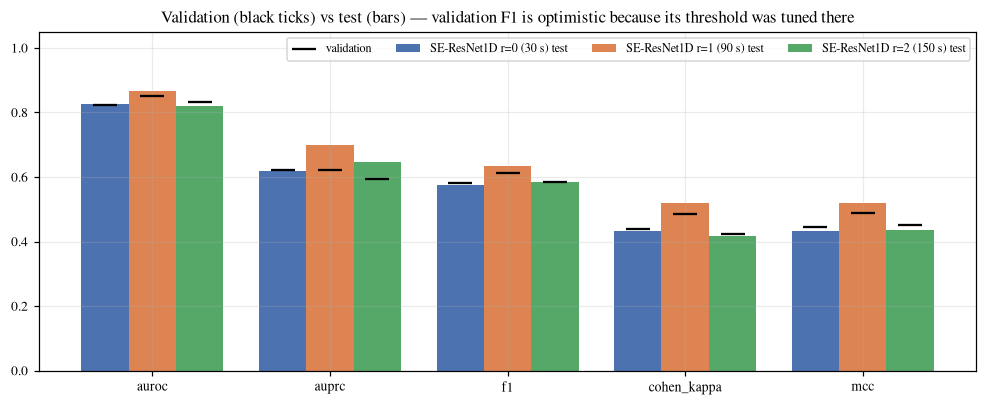

In [31]:
# F19 — generalisation gap: validation vs test (primary variant)
fig, ax = plt.subplots(figsize=(11, 4))
gap_cols = ["auroc", "auprc", "f1", "cohen_kappa", "mcc"]
xs = np.arange(len(gap_cols))
for k, r in enumerate(RADII):
    v = WIN.query("radius==@r and variant==@PRIMARY_VARIANT and split=='val'")[gap_cols].iloc[0]
    t = WIN.query("radius==@r and variant==@PRIMARY_VARIANT and split=='test'")[gap_cols].iloc[0]
    off = (k - (len(RADII) - 1) / 2) * w
    ax.bar(xs + off, t, w, color=MODEL_COLOR[r], label=f"{MODEL_LABEL[r]} test")
    ax.scatter(xs + off, v, marker="_", s=260, color="k", zorder=5,
               label="validation" if k == 0 else None)
ax.set_xticks(xs); ax.set_xticklabels(gap_cols); ax.set_ylim(0, 1.05)
ax.legend(fontsize=8, ncol=4)
ax.set_title("Validation (black ticks) vs test (bars) — validation F1 is optimistic "
             "because its threshold was tuned there")
savefig(fig, "F19_val_vs_test")

In [32]:
# =============================================================================
# 15. FINAL SUMMARY
# =============================================================================
best_r = int(HEAD.assign(r=RADII).sort_values("f1", ascending=False).r.iloc[0])
display(Markdown(f"### Summary\nPrimary decision rule: **{PRIMARY_VARIANT}**. "
                 f"Highest test F1: **{MODEL_LABEL[best_r]}**. Check T3/T12 before claiming "
                 "that any radius is *better* — overlapping CIs or Holm-adjusted p ≥ 0.05 "
                 "mean the difference is not established on this test set."))
display(HEAD.round(4))

print("\nFiles written:")
for sub in ["split", "tables", "figures"]:
    fl = sorted(os.listdir(os.path.join(OUTPUT_DIR, sub)))
    print(f"  {sub}/ ({len(fl)} files)")
    for f in fl:
        print("     ", f)
for r in RADII:
    print(f"  models/r{r}/:", sorted(os.listdir(os.path.join(MODEL_DIR, f"r{r}"))))

### Summary
Primary decision rule: **raw@0.5**. Highest test F1: **SE-ResNet1D r=1 (90 s)**. Check T3/T12 before claiming that any radius is *better* — overlapping CIs or Holm-adjusted p ≥ 0.05 mean the difference is not established on this test set.

,model,auroc,auprc,f1,cohen_kappa,mcc,sensitivity,specificity,precision,accuracy,...,true_events,pred_events,ahi_r,ahi_mae,severity_acc,severity_kappa_w,params,best_epoch,train_min,infer_ms/win
0,SE-ResNet1D r=0 (30 s),0.8252,0.6177,0.5758,0.4321,0.4339,0.6174,0.8363,0.5394,0.7844,...,825,1364,0.6294,11.4973,0.6000,0.5291,2466697,13,3.6629,0.0794
1,SE-ResNet1D r=1 (90 s),0.8662,0.6988,0.6347,0.5192,0.5193,0.6437,0.8805,0.6260,0.8244,...,825,589,0.7459,9.7981,0.6667,0.5909,2466697,6,6.4104,0.2245
2,SE-ResNet1D r=2 (150 s),0.8199,0.6475,0.5831,0.4167,0.4348,0.7327,0.7576,0.4842,0.7517,...,825,509,0.4572,14.3313,0.6000,0.4000,2466697,13,14.3501,0.3226



Files written:
  split/ (3 files)
      patient_split.csv
      split.json
      subject_ahi_mapping.csv
  tables/ (28 files)
      T0_headline_comparison.csv
      T0_headline_comparison.tex
      T0_split_summary.csv
      T0_split_summary.tex
      T0b_reproduction_vs_kaggle.csv
      T0b_reproduction_vs_kaggle.tex
      T10_training_history.csv
      T11_run_info.csv
      T11_run_info.tex
      T12_statistical_tests.csv
      T12_statistical_tests.tex
      T1_window_metrics_test.csv
      T1_window_metrics_test.tex
      T1a_window_metrics_all_variants_val_and_test.csv
      T2_bootstrap_ci_test.csv
      T2_bootstrap_ci_test.tex
      T3_bootstrap_paired_differences.csv
      T3_bootstrap_paired_differences.tex
      T4_event_level_test.csv
      T4_event_level_test.tex
      T5_ahi_agreement_test.csv
      T5_ahi_agreement_test.tex
      T6_severity_agreement_test.csv
      T6_severity_agreement_test.tex
      T7_severity_stratified_performance.csv
      T7_severity_stratified